# Classifying Mirage tactics from minimap video: which model and input?

This report compares classifiers that name the tactic of a CS2 Mirage round clip. It uses the development matches only; the test matches are never read. Every score and count is computed from saved runs when the notebook runs.

Each question shows what was tested and how to read the evidence, then the evidence, then the answer in words with one line of key numbers. Appendix A6 prints the full numbers and checks every answer. Appendix A5 lists the runs and how to reproduce them.

In [1]:
# @title Load the saved runs
import csv
import json
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle

%matplotlib inline

# Every run folder this notebook reads, listed once. Appendix A5 prints which were found;
# a missing folder leaves its table cells as "—" and its claims unverified.
RUNS = {
    # ResNet images, nested epoch selection
    "img_nested": "runs/tactic-temporal-20261116",  # mean pooling, temporal average pooling
    "img_gru_pooled_nested": "runs/tactic-gru-nested-20261120",  # Compact pooled GRU
    "img_gru_laststate_nested": "runs/tactic-gru-first-nested-20261120",  # Last-state GRU
    "img_gru_compact_laststate_nested": "runs/tactic-gru-middle-nested-20261120",  # Compact last-state GRU
    "img_thirds_unweighted": "runs/tactic-thirds-unweighted-nested-20261120",  # class weights off
    # ResNet images, other-folds epoch selection (Appendix A1)
    "img_other": "runs/tactic-temporal-other-folds-20261119",  # mean, temporal average, Last-state GRU
    "img_gru_compact_laststate_other": "runs/tactic-gru-small-other-folds-20261119",
    "img_gru_pooled_other": "runs/tactic-gru-pooled-other-folds-20261119",
    # Shared clip features: mean pooling, temporal average pooling, Compact pooled GRU
    "clip_nested": "runs/tactic-clipdata-nested-20261120",
    "clip_other": "runs/tactic-clipdata-other-folds-20261120",
    # Shared clip features: TCN and pooled classifier
    "tcn_clip_nested": "runs/tactic-tcn-clipdata-nested-20261120",
    "tcn_clip_other": "runs/tactic-tcn-clipdata-repro-20261119",  # train-only rerun
    "tcn_clip_curves": "runs/tactic-tcn-clipdata-curves-20261121",  # per-epoch curves (3.3)
    # Detector features: TCN and pooled classifier
    "tcn_det_other": "runs/tactic-tcn-repro-20261119",
    "tcn_det_nested": "runs/tactic-tcn-detector-nested-*",  # newest match, if any
    # Shuffled-label checks (the image runs above also hold their own)
    "gru_shuffled": "runs/tactic-gru-shuffled-other-folds-20261120",
    "tcn_clip_shuffled": "runs/tactic-tcn-clipdata-shuffled-20261120",
    # Random-segment control
    "random_segments": "runs/tactic-temporal-random-thirds-20261117",
}
# Training data (train-only copies; no test clip is read) for labels, review records and the
# figures in 2.2 and 2.3.
DATA = {
    "dataset": "data/processed/datasets/2026-11-16-train-only",
    "clip_data": "data/processed/clip-data-2026-11-16-train-only",
    "detections": "runs/tactic-cache",  # the detector's saved output per clip
    "labels": "labels",  # segment records of the development matches (review status)
}

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "stratscout").is_dir() and (p / "AGENTS.md").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the CV-DL repository or its notebooks folder.")
sys.path.insert(0, str(ROOT))  # the project's own code draws 2.2 and 2.3


def resolve(path):
    if "*" in path:
        found = sorted(ROOT.glob(path))
        return found[-1] if found else None
    folder = ROOT / path
    return folder if folder.is_dir() else None


runs = {name: resolve(path) for name, path in RUNS.items()}
data = {name: resolve(path) for name, path in DATA.items()}

CLASSES = ["A_DIRECT", "B_DIRECT", "A_SPLIT", "B_SPLIT", "RETAKE"]
SITE = {"A_DIRECT": "A", "A_SPLIT": "A", "B_DIRECT": "B", "B_SPLIT": "B", "RETAKE": "RETAKE"}
MATCH_NAMES = {
    "spirit-falcons-mirage-cologne-major": "Spirit vs Falcons",
    "furia-falcons-mirage-cologne-major-2026": "Furia vs Falcons",
    "mouz-betboom-mirage-iem-bejing-2026": "MOUZ vs BetBoom",
    "aurora-vitality-mirage-esl-pro-league-season-24": "Aurora vs Vitality",
}
MODELS = ["Mean pooling", "Temporal average pooling (3 segments)", "Compact pooled GRU", "TCN", "Pooled classifier"]
INPUTS = ["ResNet images", "Detector features", "Shared clip features"]
COLOURS = {"ResNet images": "#6baed6", "Detector features": "#fd8d3c", "Shared clip features": "#41ab5d"}
GRU_NAMES = {"laststate": "Last-state GRU", "compact_laststate": "Compact last-state GRU", "compact_pooled": "Compact pooled GRU"}
DASH = "—"
FONT = "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;"
TOLERANCE = 1e-9
E = {}  # evidence each exhibit leaves for its key line and for Appendix A6


def show_table(name, df, decimals=3):
    """Text columns left, number columns right; scores to three decimals; no index. `name`
    is the table's fixed HTML id, so rerunning the notebook leaves the saved output unchanged."""
    def is_number(column):
        values = [v for v in df[column] if not (isinstance(v, str) and (v == DASH or v.startswith(DASH)))]
        return bool(values) and all(
            isinstance(v, (int, float, np.number)) and not isinstance(v, bool)
            or isinstance(v, str) and (v[:1].isdigit() or v[:1] in "+-") and "vs" not in v
            for v in values
        )

    numbers = [c for c in df.columns if is_number(c)]
    fmt_ = {c: (lambda v, d=decimals: v if isinstance(v, str) else f"{v:d}" if isinstance(v, (int, np.integer)) else f"{v:.{d}f}") for c in numbers}
    styles = [
        {"selector": "th", "props": FONT + " font-weight: 600; padding: 4px 10px; border-bottom: 1px solid #999;"},
        {"selector": "td", "props": FONT + " padding: 4px 10px;"},
    ]
    for i, column in enumerate(df.columns):
        styles.append({"selector": f"th.col_heading.col{i}", "props": f"text-align: {'right' if column in numbers else 'left'};"})
    styler = df.style.set_uuid(name).hide(axis="index").format(fmt_).set_table_styles(styles)
    text = [c for c in df.columns if c not in numbers]
    if text:
        styler = styler.set_properties(subset=text, **{"text-align": "left"})
    if numbers:
        styler = styler.set_properties(subset=numbers, **{"text-align": "right"})
    display(HTML(styler.to_html()))  # HTML only: the Styler's text form holds a memory address


def say(text):
    display(Markdown(text))


def bullets(items):
    say("\n".join(f"- {item}" for item in items))


def claims(checks):
    """Each check is (claim, test, *evidence). A claim whose evidence is missing (None) is
    reported as unverified, never as checked; a claim that fails stops the notebook."""
    checked, unverified = [], []
    for claim, test, *evidence in checks:
        if test is None or any(e is None for e in evidence):
            unverified.append(claim)
            continue
        if not test():
            raise AssertionError(f"The answer above no longer holds: {claim}")
        checked.append(claim)
    say(
        ("**Checked:** " + "; ".join(checked) + "." if checked else "")
        + ("\n\n**Unverified (evidence missing or not checkable here):** " + "; ".join(unverified) + "." if unverified else "")
    )


def inp(i):
    """An input name inside a sentence: lower case, except ResNet."""
    return i if i.startswith("ResNet") else i.lower()


def fmt(r):
    return f"{r['mean']:.3f} ± {r['sd']:.3f}" if r else DASH


def match_of(clip_id):
    return clip_id.split(".")[0]


def confusion(truth, predicted):
    matrix = np.zeros((5, 5), int)
    np.add.at(matrix, (np.asarray(truth, int), np.asarray(predicted, int)), 1)
    return matrix


def f1_per_class(matrix):
    return {c: (2 * matrix[i, i] / (matrix[i].sum() + matrix[:, i].sum()) if matrix[i].sum() + matrix[:, i].sum() else 0.0) for i, c in enumerate(CLASSES)}


def macro_f1(truth, predicted):
    """Mean F1 over the classes present in truth (the projects' definition; every held-out
    match here has every class, where both of its implementations agree)."""
    matrix = confusion(truth, predicted)
    f1 = f1_per_class(matrix)
    return float(np.mean([f1[c] for i, c in enumerate(CLASSES) if matrix[i].sum()]))


# The training manifest, read directly; any non-training clip stops the notebook.
TRAIN = {}
if data["dataset"]:
    manifest = data["dataset"] / "train" / "manifest.csv"
    with manifest.open(encoding="utf-8", newline="") as stream:
        for row in csv.DictReader(stream):
            if row.get("split") != "train":
                raise ValueError(f"{manifest} lists a non-training clip; use the train-only copy")
            TRAIN[row["clip_id"]] = row
INCLUDED = {c: r for c, r in TRAIN.items() if r["boundary_uncertain"].strip().lower() == "false"}

AUDIT = []  # (result, check, passed or None when the evidence is missing)
AGREE = []  # (result, quantity, recomputed, saved, kind)


def audit(label, check, passed):
    AUDIT.append((label, check, None if passed is None else bool(passed)))


def agree(label, quantity, ours, saved, kind):
    if saved is not None:
        AGREE.append((label, quantity, ours, saved, kind))


def finish(result):
    """Per seed, the mean over held-out matches; then mean and SD over seeds; per match, the
    mean over seeds. Pooled scores come from the seed ensemble over every clip."""
    pairs, seeds = result["pairs"], result["seeds"]
    matches = sorted(result["clips"])
    per_seed = [float(np.mean([pairs[(m, s)] for m in matches])) for s in seeds]
    pooled = f1_per_class(result["confusion"])
    result.update(
        per_seed=per_seed,
        mean=float(np.mean(per_seed)),
        sd=float(np.std(per_seed)),
        per_match={m: float(np.mean([pairs[(m, s)] for s in seeds])) for m in matches},
        pooled_f1=pooled,
        pooled_macro=float(np.mean(list(pooled.values()))),
    )
    return result


def read_temporal(key, model):
    """One tactic-temporal model folder (any input, either epoch selection). Scores are
    recomputed from predictions.csv after checking it against the fold records."""
    folder = runs.get(key)
    if folder is None or not (folder / model / "summary.json").is_file():
        return None
    model_dir, label = folder / model, f"{folder.name}/{model}"
    config = json.loads((model_dir / "config.json").read_text(encoding="utf-8"))
    seeds = list(config["settings"]["seeds"])
    folds = {}
    for path in sorted(model_dir.glob("fold-[0-9].json")):
        fold = json.loads(path.read_text(encoding="utf-8"))
        folds[fold["fold"]] = fold
    with (model_dir / "predictions.csv").open(encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    keys = [(r["clip_id"], int(r["seed"])) for r in rows]
    audit(label, "(clip_id, seed) keys are unique", len(keys) == len(set(keys)))
    audit(label, "(clip_id, seed) keys are complete", set(keys) == {(c, s) for f in folds.values() for c in f["validation_clip_ids"] for s in seeds})
    audit(label, "labels match the training manifest", all(r["clip_id"] in TRAIN and TRAIN[r["clip_id"]]["label"] == r["truth"] for r in rows) if TRAIN else None)
    audit(label, "fold membership in predictions.csv matches the fold records",
          {int(r["fold"]) for r in rows} == set(folds) and all(r["clip_id"] in folds[int(r["fold"])]["validation_clip_ids"] for r in rows))
    epoch_of = {(k, run["seed"]): run["evaluation_epoch"] for k, f in folds.items() for run in f["runs"]}
    audit(label, "epoch metadata is present and matches the fold records",
          all(r["evaluation_epoch"].strip() and int(r["evaluation_epoch"]) == epoch_of[(int(r["fold"]), int(r["seed"]))] for r in rows))
    probs_of = lambda r: np.array([float(r[f"p_{c}"]) for c in CLASSES])
    audit(label, "the predicted column is the most probable class", all(CLASSES[int(probs_of(r).argmax())] == r["predicted"] for r in rows))
    pairs, epochs, by_fold_seed = {}, {}, defaultdict(list)
    for r in rows:
        by_fold_seed[(int(r["fold"]), int(r["seed"]))].append(r)
    for (k, s), group in by_fold_seed.items():
        match = match_of(folds[k]["validation_clip_ids"][0])
        pairs[(match, s)] = macro_f1([CLASSES.index(r["truth"]) for r in group], [int(probs_of(r).argmax()) for r in group])
        saved = next(run["metrics"]["macro_f1"] for run in folds[k]["runs"] if run["seed"] == s)
        agree(label, f"fold {k}, seed {s}", pairs[(match, s)], saved, "fold record")
        epochs.setdefault(match, []).append(epoch_of[(k, s)])
    inner = None
    if config["epoch_mode"] == "nested":
        inner = []
        for f in folds.values():
            for run in f["runs"]:
                ids = (run.get("selection") or {}).get("inner_validation_match_ids")
                inner.append(None if ids is None else f["validation_match_id"] not in ids and set(ids) == set(f["train_match_ids"]))
    by_clip = {}
    for r in rows:
        by_clip.setdefault(r["clip_id"], (r["truth"], []))[1].append(probs_of(r))
    clip_rows = [dict(clip_id=c, truth=CLASSES.index(t), probs=np.mean(p, axis=0)) for c, (t, p) in by_clip.items()]
    result = finish(
        dict(
            source=label, rule=config["epoch_mode"], seeds=seeds, pairs=pairs, epochs=epochs, inner=inner,
            clips={match_of(f["validation_clip_ids"][0]): sorted(f["validation_clip_ids"]) for f in folds.values()},
            clip_rows=clip_rows, config=config, per_seed_source="recomputed from predictions.csv",
            confusion=confusion([r["truth"] for r in clip_rows], [int(r["probs"].argmax()) for r in clip_rows]),
        )
    )
    summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    saved = summary["models"][model]
    result["majority"] = saved.get("majority")
    agree(label, "mean", result["mean"], saved["macro_f1"]["mean"], "summary report")
    agree(label, "seed SD", result["sd"], saved["macro_f1"]["std"], "summary report")
    agree(label, "seed-ensemble macro-F1", result["pooled_macro"], (saved.get("seed_ensemble") or {}).get("macro_f1"), "summary report")
    return result


def read_tcn_nested(key, kind):
    """scripts/nested_tcn.py output: one JSON per model and outer match, holding every seed's
    held-out probabilities. Scores are recomputed from those probabilities."""
    folder = runs.get(key)
    paths = sorted(folder.glob(f"{kind}-*.json")) if folder else []
    if len(paths) != 4:
        return None
    parts = [json.loads(p.read_text(encoding="utf-8")) for p in paths]
    outer_matches = {p["outer_match"] for p in parts}
    pairs, clips, epochs, clip_rows, inner = {}, {}, {}, [], []
    for part in parts:
        match, label = part["outer_match"], f"{folder.name}/{kind}-{part['outer_match']}"
        ids, seeds = part["clip_ids"], [s["seed"] for s in part["seeds"]]
        audit(label, "(clip_id, seed) keys are unique", len(ids) == len(set(ids)) and len(seeds) == len(set(seeds)))
        audit(label, "(clip_id, seed) keys are complete",
              (set(ids) == {c for c in INCLUDED if match_of(c) == match} and seeds == list(part["config"]["seeds"])) if TRAIN else None)
        audit(label, "labels match the training manifest", all(c in TRAIN and TRAIN[c]["label"] == CLASSES[y] for c, y in zip(ids, part["y"])) if TRAIN else None)
        audit(label, "every clip belongs to the held-out match of its file", all(match_of(c) == match for c in ids))
        audit(label, "epoch metadata is present", isinstance(part.get("chosen_epochs"), int) and part["chosen_epochs"] > 0)
        audit(label, "every seed has one probability row per clip", all(len(s["probs"]) == len(ids) for s in part["seeds"]))
        inner.append(match not in part["inner_matches"] and set(part["inner_matches"]) == outer_matches - {match})
        clips[match] = sorted(ids)
        epochs[match] = [part["chosen_epochs"]] * len(seeds)
        for s in part["seeds"]:
            pairs[(match, s["seed"])] = macro_f1(part["y"], np.asarray(s["probs"]).argmax(1))
            agree(label, f"seed {s['seed']}", pairs[(match, s["seed"])], s["macro_f1"], "fold record")
        mean_probs = np.mean([s["probs"] for s in part["seeds"]], axis=0)
        clip_rows += [dict(clip_id=c, truth=t, probs=p) for c, t, p in zip(ids, part["y"], mean_probs)]
    config = parts[0]["config"]
    result = finish(
        dict(
            source=f"{folder.name}/{kind}-*.json", rule="nested", seeds=list(config["seeds"]), pairs=pairs, clips=clips,
            epochs=epochs, clip_rows=clip_rows, config=config, inner=inner, per_seed_source="recomputed from the saved per-seed probabilities",
            confusion=confusion([r["truth"] for r in clip_rows], [int(r["probs"].argmax()) for r in clip_rows]),
        )
    )
    summary = folder / "summary.json"
    if summary.is_file():
        saved = json.loads(summary.read_text(encoding="utf-8"))["models"][kind]
        agree(result["source"], "mean", result["mean"], saved["nested_macro_f1_mean_over_seeds"], "summary report")
        agree(result["source"], "seed SD", result["sd"], saved["nested_macro_f1_seed_sd"], "summary report")
        agree(result["source"], "seed-ensemble macro-F1", result["pooled_macro"], saved["ensemble_macro_f1"], "summary report")
        for m, value in saved["per_match_macro_f1"].items():
            agree(result["source"], f"{m} macro-F1", result["per_match"][m], value, "summary report")
    return result


def read_tcn_other(key, kind):
    """train-tactics cross-validation (other-folds epoch selection). Test results are never
    read. Only seed-ensemble predictions were saved, so per-seed scores come from the saved
    cross-validation history; the ensemble is recomputed from cv_predictions.csv."""
    folder = runs.get(key)
    if folder is None or not (folder / "report.json").is_file():
        return None
    report = json.loads((folder / "report.json").read_text(encoding="utf-8"))
    if kind not in report["models"]:
        return None
    label = f"{folder.name} ({kind})"
    cv = report["models"][kind]["cv"]
    pairs = {}
    for run in report["models"][kind]["cv_runs"]:
        epoch = cv["cross_fold_epochs"][run["held_out"]]
        pairs[(run["held_out"], run["seed"])] = dict(run["history"])[epoch]
    with (folder / "cv_predictions.csv").open(encoding="utf-8") as stream:
        rows = [r for r in csv.DictReader(stream) if r["model"] == kind]
    ids = [r["clip_id"] for r in rows]
    audit(label, "clip_id keys are unique", len(ids) == len(set(ids)))
    audit(label, "clip_id keys are complete", set(ids) == set(INCLUDED) if TRAIN else None)
    audit(label, "labels match the training manifest", all(r["clip_id"] in TRAIN and TRAIN[r["clip_id"]]["label"] == r["true"] for r in rows) if TRAIN else None)
    audit(label, "the match column matches each clip", all(match_of(r["clip_id"]) == r["match"] for r in rows))
    audit(label, "epoch metadata is present for every held-out match", set(cv["cross_fold_epochs"]) == {r["match"] for r in rows})
    clip_rows = [dict(clip_id=r["clip_id"], truth=CLASSES.index(r["true"]), probs=np.array([float(r[f"p_{c}"]) for c in CLASSES])) for r in rows]
    clips = defaultdict(list)
    for r in rows:
        clips[r["match"]].append(r["clip_id"])
    result = finish(
        dict(
            source=label, rule="other-folds", seeds=list(report["config"]["seeds"]), pairs=pairs,
            clips={m: sorted(v) for m, v in clips.items()}, inner=None, config=report["config"],
            epochs={m: [e] * len(report["config"]["seeds"]) for m, e in cv["cross_fold_epochs"].items()},
            clip_rows=clip_rows, per_seed_source="saved cross-validation history (per-seed predictions not saved)",
            confusion=confusion([r["truth"] for r in clip_rows], [int(r["probs"].argmax()) for r in clip_rows]),
        )
    )
    agree(label, "seed-ensemble macro-F1 (recomputed from cv_predictions.csv)", result["pooled_macro"], cv["pooled"]["ensemble"]["macro_f1"], "summary report")
    agree(label, "mean", result["mean"], cv["cross_fold_macro_f1"], "summary report")
    for m, value in cv["per_fold_macro_f1"].items():
        agree(label, f"{m} macro-F1", result["per_match"][m], value, "summary report")
    return result


# Main results: (model, input, epoch selection) -> result. Missing runs are left out.
LOADERS = {
    ("Mean pooling", "ResNet images", "nested"): lambda: read_temporal("img_nested", "mean"),
    ("Temporal average pooling (3 segments)", "ResNet images", "nested"): lambda: read_temporal("img_nested", "thirds"),
    ("Compact pooled GRU", "ResNet images", "nested"): lambda: read_temporal("img_gru_pooled_nested", "gru"),
    ("Mean pooling", "ResNet images", "other-folds"): lambda: read_temporal("img_other", "mean"),
    ("Temporal average pooling (3 segments)", "ResNet images", "other-folds"): lambda: read_temporal("img_other", "thirds"),
    ("Compact pooled GRU", "ResNet images", "other-folds"): lambda: read_temporal("img_gru_pooled_other", "gru"),
    ("Mean pooling", "Shared clip features", "nested"): lambda: read_temporal("clip_nested", "mean"),
    ("Temporal average pooling (3 segments)", "Shared clip features", "nested"): lambda: read_temporal("clip_nested", "thirds"),
    ("Compact pooled GRU", "Shared clip features", "nested"): lambda: read_temporal("clip_nested", "gru"),
    ("Mean pooling", "Shared clip features", "other-folds"): lambda: read_temporal("clip_other", "mean"),
    ("Temporal average pooling (3 segments)", "Shared clip features", "other-folds"): lambda: read_temporal("clip_other", "thirds"),
    ("Compact pooled GRU", "Shared clip features", "other-folds"): lambda: read_temporal("clip_other", "gru"),
    ("TCN", "Shared clip features", "nested"): lambda: read_tcn_nested("tcn_clip_nested", "tcn"),
    ("Pooled classifier", "Shared clip features", "nested"): lambda: read_tcn_nested("tcn_clip_nested", "control"),
    ("TCN", "Shared clip features", "other-folds"): lambda: read_tcn_other("tcn_clip_other", "tcn"),
    ("Pooled classifier", "Shared clip features", "other-folds"): lambda: read_tcn_other("tcn_clip_other", "control"),
    ("TCN", "Detector features", "nested"): lambda: read_tcn_nested("tcn_det_nested", "tcn"),
    ("Pooled classifier", "Detector features", "nested"): lambda: read_tcn_nested("tcn_det_nested", "control"),
    ("TCN", "Detector features", "other-folds"): lambda: read_tcn_other("tcn_det_other", "tcn"),
    ("Pooled classifier", "Detector features", "other-folds"): lambda: read_tcn_other("tcn_det_other", "control"),
}
# The three GRU designs on ResNet images, both epoch selections.
GRU_VERSIONS = {
    "laststate": ("img_gru_laststate_nested", "img_other"),
    "compact_laststate": ("img_gru_compact_laststate_nested", "img_gru_compact_laststate_other"),
    "compact_pooled": ("img_gru_pooled_nested", "img_gru_pooled_other"),
}
results = {key: load() for key, load in LOADERS.items()}
results = {key: value for key, value in results.items() if value is not None}
gru_versions = {
    version: {"nested": read_temporal(nested, "gru"), "other-folds": read_temporal(other, "gru")}
    for version, (nested, other) in GRU_VERSIONS.items()
}
unweighted = read_temporal("img_thirds_unweighted", "thirds")
random_segments = read_temporal("random_segments", "random-thirds")
tcn_curves = (
    json.loads((runs["tcn_clip_curves"] / "curves.json").read_text(encoding="utf-8"))
    if runs["tcn_clip_curves"] and (runs["tcn_clip_curves"] / "curves.json").is_file()
    else None
)

In [2]:
# @title Check and compute results
# 1. Prediction files: unique and complete keys, labels, fold membership, epoch metadata.
failed = [f"{label}: {check}" for label, check, passed in AUDIT if passed is False]
if failed:
    raise ValueError("Prediction-file checks failed:\n" + "\n".join(failed))
# 2. Scores recomputed from the predictions must equal the fold records, and the saved
#    summary reports must agree with them.
for label, quantity, ours, saved, kind in AGREE:
    if abs(ours - saved) > TOLERANCE:
        raise ValueError(f"{label}: {quantity} recomputed {ours!r}, {kind} says {saved!r}")

# 3. The same clips, folds, seeds and epoch selection for every result, or stop here.
everything = list(results.items()) + [
    ((GRU_NAMES[v], "ResNet images", rule), r) for v, d in gru_versions.items() for rule, r in d.items() if r
] + [
    (("Temporal average pooling, class weights off", "ResNet images", "nested"), unweighted),
    (("Random-segment control", "ResNet images", "nested"), random_segments),
]
everything = [(k, r) for k, r in everything if r is not None]
reference = results[("Mean pooling", "ResNet images", "nested")]["clips"]
for (model, inputs, rule), r in everything:
    if r["clips"] != reference:
        raise ValueError(f"{model} on {inputs} ({rule}) uses other clips or folds than the reference")
    if r["seeds"] != [0, 1, 2]:
        raise ValueError(f"{model} on {inputs} ({rule}) uses seeds {r['seeds']}")
    if r["rule"] != rule:
        raise ValueError(f"{model} on {inputs}: saved epoch selection {r['rule']!r}, expected {rule!r}")
if INCLUDED and {c for v in reference.values() for c in v} != set(INCLUDED):
    raise ValueError("The runs' clips differ from the included clips of the training manifest")

N_CLIPS = sum(len(v) for v in reference.values())
MATCHES = list(MATCH_NAMES)
N_SEEDS = len(results[("Mean pooling", "ResNet images", "nested")]["seeds"])
nested = {(m, i): r for (m, i, rule), r in results.items() if rule == "nested"}
best_key = max(nested, key=lambda k: nested[k]["mean"])

# Clips per class and match, from the saved folds.
by_match = {}
for path in sorted((runs["img_nested"] / "mean").glob("fold-[0-9].json")):
    fold = json.loads(path.read_text(encoding="utf-8"))
    by_match[match_of(fold["validation_clip_ids"][0])] = fold["validation_counts"]
totals = {c: sum(by_match[m][c] for m in MATCHES) for c in CLASSES}
small, large = min(totals, key=totals.get), max(totals, key=totals.get)
majority = results[("Mean pooling", "ResNet images", "nested")]["majority"]

# Inputs: sampling and widths, from the saved runs.
image_config = results[("Mean pooling", "ResNet images", "nested")]["config"]
n_frames = image_config["settings"]["n_frames"]
resnet_width = (image_config["trainable_parameters"] - len(CLASSES)) // len(CLASSES)  # a linear head on the frame mean
clip_summary = json.loads((runs["clip_nested"] / "summary.json").read_text(encoding="utf-8"))
detector_channels = clip_summary["clip_data"]["detector_channels"]
pcs = clip_summary["clip_data"]["resnet_pcs"]
rows_per_clip = {s["clip_id"]: s["rows"] for s in json.loads((runs["clip_nested"] / "samples.json").read_text(encoding="utf-8"))}
with (runs["clip_nested"] / "input-manifest.csv").open(encoding="utf-8-sig") as stream:
    durations = {r["clip_id"]: float(r["duration_s"]) for r in csv.DictReader(stream)}
rate = float(np.median([rows_per_clip[c] / durations[c] for c in rows_per_clip]))

# Model-on-input comparisons used by the summary and section 4.
both = [m for m in MODELS if (m, "ResNet images") in nested and (m, "Shared clip features") in nested]
changes = {m: nested[(m, "Shared clip features")]["mean"] - nested[(m, "ResNet images")]["mean"] for m in both}
clip_models = {m: nested[(m, "Shared clip features")] for m in MODELS if (m, "Shared clip features") in nested}
clip_spread = max(r["mean"] for r in clip_models.values()) - min(r["mean"] for r in clip_models.values())
spreads = {k: max(r["per_match"].values()) - min(r["per_match"].values()) for k, r in nested.items()}

# Example clips for 2.2 and 2.3, from the training manifest: in the first development match
# (alphabetically), the first A_SPLIT and the first A_DIRECT clip by clip number.
EXAMPLE_MATCH = sorted(MATCHES)[0]
example_rows = {}
for label in ("A_SPLIT", "A_DIRECT"):
    found = sorted(c for c, r in INCLUDED.items() if r["match_folder"] == EXAMPLE_MATCH and r["label"] == label)
    if found:
        example_rows[label] = dict(clip_id=found[0], label=label, match=EXAMPLE_MATCH, path=data["dataset"] / "train" / INCLUDED[found[0]]["clip"])

## Summary

In [3]:
# @title Summary: task, strongest result, main finding
best_model, best_input = best_key
if both:
    finding = (
        f"Changing the input from ResNet images ({n_frames} sampled frames per clip) to shared clip features "
        f"({rate:.0f} rows per second) raised nested macro-F1 by {min(changes.values()):+.3f} to {max(changes.values()):+.3f} "
        f"for the {len(both)} models run on both; these gains include the change in sampling as well as the richer input. "
        f"Across the {len(clip_models)} models on shared clip features, scores differ by at most {clip_spread:.3f}."
    )
else:
    finding = "No model has nested runs on both ResNet images and shared clip features yet."
say(
    f"- **Task:** name the tactic of {N_CLIPS} hand-cut Mirage clips from {len(MATCHES)} development matches "
    f"({len(CLASSES)} classes), training on all but one match and testing on the match left out.\n"
    f"- **Strongest completed nested result:** {best_model} on {inp(best_input)}, nested macro-F1 {fmt(nested[best_key])} "
    f"(mean over {len(reference)} held-out matches × {N_SEEDS} seeds; ± is the SD over seeds).\n"
    f"- **Main comparison finding:** {finding}"
)

- **Task:** name the tactic of 82 hand-cut Mirage clips from 4 development matches (5 classes), training on all but one match and testing on the match left out.
- **Strongest completed nested result:** TCN on shared clip features, nested macro-F1 0.849 ± 0.021 (mean over 4 held-out matches × 3 seeds; ± is the SD over seeds).
- **Main comparison finding:** Changing the input from ResNet images (16 sampled frames per clip) to shared clip features (5 rows per second) raised nested macro-F1 by +0.143 to +0.278 for the 3 models run on both; these gains include the change in sampling as well as the richer input. Across the 5 models on shared clip features, scores differ by at most 0.086.

## 1. Task and data

### 1.1 What is the task?

Each clip is one attack or one retake from a professional CS2 match on Mirage, seen through the spectator minimap (the small overhead map of the whole level). A model sees one clip and must choose one of five classes. Terms used throughout:

- **T** (terrorists) attack and try to plant the bomb; **CT** (counter-terrorists) defend.
- A **site** is one of the two places where the bomb can be planted, **A** or **B**.
- A **direct** attack goes onto a site by one route; a **split** attack combines two routes onto the same site at the same time.
- A **retake** is the CTs trying to win a site back after the bomb has been planted there.

The table lists the classes, one line each; full rules are in the [tactic definitions](../docs/tactic-definitions.md).

In [4]:
# @title Table: the five classes
show_table("classes", 
    pd.DataFrame(
        [
            ["A_DIRECT", "A", "Ts attack A through ramp and/or palace, without a coordinated push from mid through connector."],
            ["B_DIRECT", "B", "Ts attack B through apartments, without a coordinated push from mid through short."],
            ["A_SPLIT", "A", "An attack through ramp and/or palace combined with one from mid through connector, in the same engagement."],
            ["B_SPLIT", "B", "An attack through apartments combined with one from mid through short, in the same engagement."],
            ["RETAKE", "A or B", "After a plant, CTs try to win the site back (success not required)."],
        ],
        columns=["Class", "Site", "What happens"],
    )
)

Class,Site,What happens
A_DIRECT,A,"Ts attack A through ramp and/or palace, without a coordinated push from mid through connector."
B_DIRECT,B,"Ts attack B through apartments, without a coordinated push from mid through short."
A_SPLIT,A,"An attack through ramp and/or palace combined with one from mid through connector, in the same engagement."
B_SPLIT,B,"An attack through apartments combined with one from mid through short, in the same engagement."
RETAKE,A or B,"After a plant, CTs try to win the site back (success not required)."


**Answer.** Split and direct attacks end on the same site; the difference is a second group. If the Ts hit A only from ramp and palace, the clip is A_DIRECT. If another group pushes from mid through connector onto A at the same time, it is A_SPLIT (on B: apartments, plus mid through short).

### 1.2 What data do the models learn from?

Match demos were replayed in CS2 and the minimap was screen-recorded ([recording guide](../docs/recording-setup.md)). A labeller marked the start and end of each attack or retake on the video and chose its class ([labelling guide](../docs/labelling-guide.md), [tactic definitions](../docs/tactic-definitions.md)); clips marked uncertain are left out. The paragraph below states how the labels were reviewed, with counts from the label records. The figure shows the included clips per class, with each bar split by match, so bar height is the class total; the table gives the same counts.

**Review.** All 82 included clips were marked reviewed before export. For two matches (Furia and Spirit), a second team member reviewed and approved the segments (42 clips; 1 more clip was marked reviewed by the labeller). For the other two (Aurora and MOUZ), the labeller marked the segments reviewed after a second team member answered the flagged uncertain rounds ([review notes](../labels/review-notes.md)); the remaining clips in those matches were not independently re-checked.

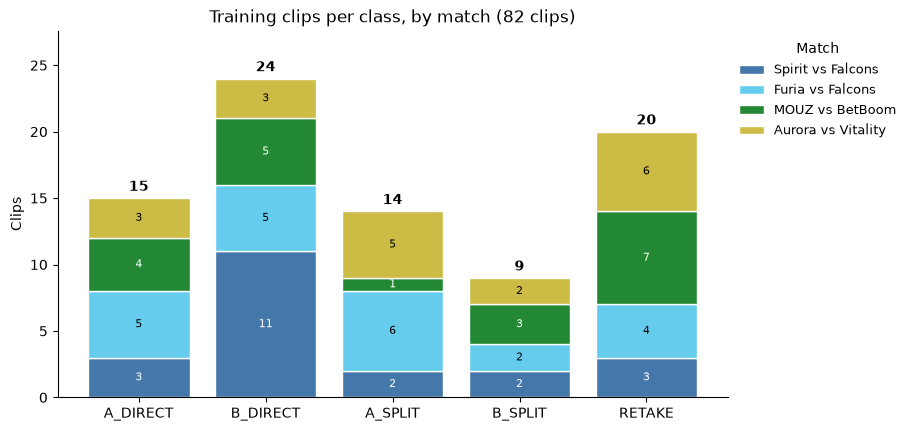

Class,Spirit vs Falcons,Furia vs Falcons,MOUZ vs BetBoom,Aurora vs Vitality,Total
A_DIRECT,3,5,4,3,15
B_DIRECT,11,5,5,3,24
A_SPLIT,2,6,1,5,14
B_SPLIT,2,2,3,2,9
RETAKE,3,4,7,6,20
All classes,21,22,20,19,82


In [5]:
# @title Review status, figure and table: clips per class and match
review = None
if data["labels"] and INCLUDED:
    review = {}
    for m in MATCHES:
        records = sorted(data["labels"].glob(f"{m}.*segments.json"))
        if len(records) != 1:
            review = None
            break
        segments = {int(s["id"]): s for s in json.loads(records[0].read_text(encoding="utf-8"))["segments"]}
        clips = [r for r in INCLUDED.values() if r["match_folder"] == m]
        chosen = [segments[int(r["segment_id"])] for r in clips]
        review[m] = dict(
            clips=len(clips),
            reviewed=sum(s["status"] == "reviewed" for s in chosen),
            second=sum(s["status"] == "reviewed" and s.get("reviewed_by") not in (None, s.get("reviewer")) for s in chosen),
        )
E["q12"] = dict(review=review)
if review:
    pair = ["furia-falcons-mirage-cologne-major-2026", "spirit-falcons-mirage-cologne-major"]
    others = ["aurora-vitality-mirage-esl-pro-league-season-24", "mouz-betboom-mirage-iem-bejing-2026"]
    n_pair, n_second = sum(review[m]["clips"] for m in pair), sum(review[m]["second"] for m in pair)
    say(
        f"**Review.** All {sum(v['reviewed'] for v in review.values())} included clips were marked reviewed before export. "
        f"For two matches (Furia and Spirit), a second team member reviewed and approved the segments ({n_second} clips"
        + (f"; {n_pair - n_second} more clip{'s were' if n_pair - n_second != 1 else ' was'} marked reviewed by the labeller" if n_pair > n_second else "")
        + "). For the other two (Aurora and MOUZ), the labeller marked the segments reviewed after a second team member answered "
        "the flagged uncertain rounds ([review notes](../labels/review-notes.md)); the remaining clips in those matches were not "
        "independently re-checked."
    )
else:
    say(f"{DASH} The label records or the training manifest are not available (Appendix A5).")
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
bottom = np.zeros(len(CLASSES))
palette = ["#4477AA", "#66CCEE", "#228833", "#CCBB44"]
for colour, m in zip(palette, MATCHES):
    counts = np.array([by_match[m][c] for c in CLASSES])
    ax.bar(CLASSES, counts, bottom=bottom, color=colour, edgecolor="white", label=MATCH_NAMES[m])
    for x, (b, n) in enumerate(zip(bottom, counts)):
        if n:
            ax.text(x, b + n / 2, n, ha="center", va="center", fontsize=8, color="white" if colour in ("#4477AA", "#228833") else "black")
    bottom += counts
for x, total in enumerate(bottom):
    ax.text(x, total + 0.3, int(total), ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("Clips")
ax.set_title(f"Training clips per class, by match ({N_CLIPS} clips)")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0), title="Match")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, bottom.max() * 1.15)
plt.show()
show_table("clips-per-class", 
    pd.DataFrame(
        [[c] + [by_match[m][c] for m in MATCHES] + [totals[c]] for c in CLASSES]
        + [["All classes"] + [sum(by_match[m].values()) for m in MATCHES] + [N_CLIPS]],
        columns=["Class"] + [MATCH_NAMES[m] for m in MATCHES] + ["Total"],
    )
)

**Answer.** The classes are uneven: B_DIRECT is the largest class and B_SPLIT the smallest. Every match has clips of every class, but the mix differs between matches; in Spirit vs Falcons, B_DIRECT makes up about half of the clips. Review was independent for two matches and only partial for the other two (see the review paragraph).

In [6]:
# @title Key numbers
say(f"{N_CLIPS} included clips; largest class {large} ({totals[large]}), smallest {small} ({totals[small]}).")

82 included clips; largest class B_DIRECT (24), smallest B_SPLIT (9).

### 1.3 Why macro-F1?

Two scores are compared for a lazy model that always answers the largest class: accuracy (the share of clips it gets right) and macro-F1 (the F1 score of each class, averaged with equal weight). A good main score should not reward this lazy model.

In [7]:
# @title Table: accuracy and macro-F1 of always answering the largest class
always = np.zeros((5, 5), int)
for i, c in enumerate(CLASSES):
    always[i, CLASSES.index(large)] = totals[c]
E["q13"] = dict(accuracy=totals[large] / N_CLIPS, macro=float(np.mean(list(f1_per_class(always).values()))))
show_table("majority-baseline", 
    pd.DataFrame(
        [[f"Always {large} (all {N_CLIPS} clips pooled)", E["q13"]["accuracy"], E["q13"]["macro"]]]
        + ([["Majority class of each fold's training matches (mean over held-out matches)", majority["accuracy"], majority["macro_f1"]]] if majority else []),
        columns=["Lazy model", "Accuracy", "Macro-F1"],
    )
)

Lazy model,Accuracy,Macro-F1
Always B_DIRECT (all 82 clips pooled),0.293,0.091
Majority class of each fold's training matches (mean over held-out matches),0.195,0.065


**Answer.** Accuracy rewards answering the large classes, so a model that ignores every small class still looks reasonable. Macro-F1 gives each tactic the same weight, so the lazy model scores close to zero. Macro-F1 is therefore the main score throughout this report.

In [8]:
# @title Key numbers
say(f"Always {large}: accuracy {E['q13']['accuracy']:.3f}, macro-F1 {E['q13']['macro']:.3f}.")

Always B_DIRECT: accuracy 0.293, macro-F1 0.091.

## 2. Pipeline and evaluation

### 2.1 How does a clip become a prediction?

The diagram follows one clip from video to class. ResNet-18 (pretrained on ImageNet photos) and the rule-based icon detector are fixed; only the classifier at the end is trained.

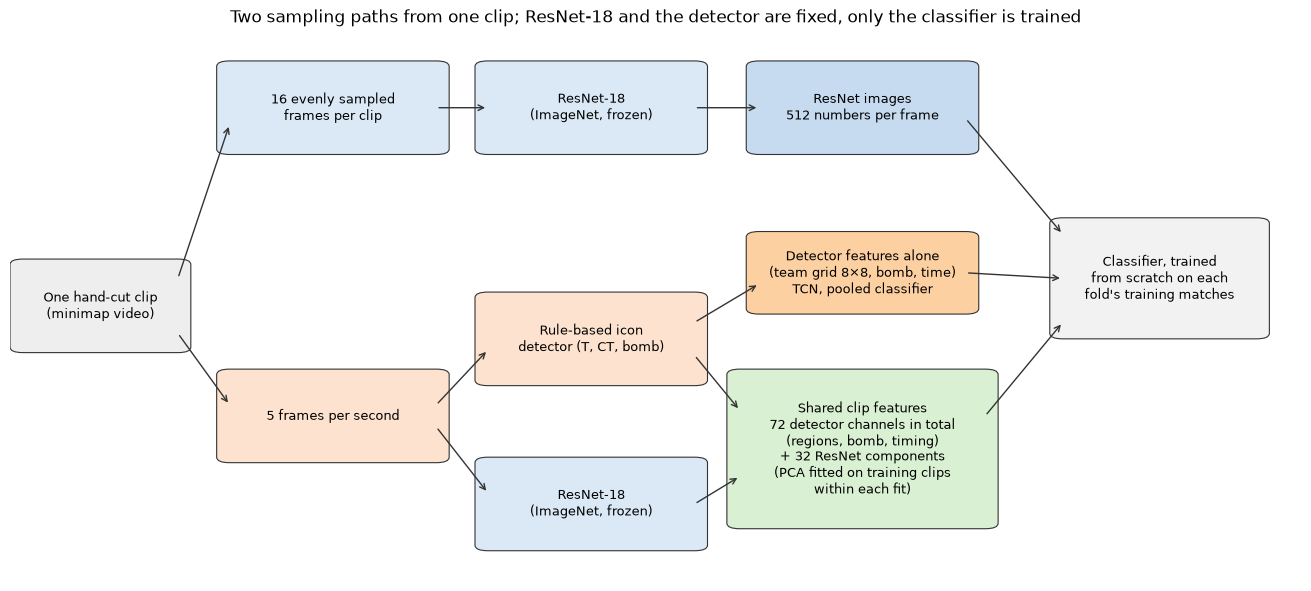

In [9]:
# @title Figure: the two sampling paths from one clip
grid = results[("TCN", "Detector features", "other-folds")]["config"]["grid"] if ("TCN", "Detector features", "other-folds") in results else None
fig, ax = plt.subplots(figsize=(13, 5.8), layout="constrained")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")


def box(x, y, text, colour, width=0.16, height=0.15):
    ax.add_patch(FancyBboxPatch((x - width / 2, y - height / 2), width, height, boxstyle="round,pad=0.01", facecolor=colour, edgecolor="#333333", linewidth=0.8))
    ax.text(x, y, text, ha="center", va="center", fontsize=9)


def arrow(a, b):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="#333333", linewidth=1))


box(0.07, 0.5, "One hand-cut clip\n(minimap video)", "#eeeeee", width=0.12)
box(0.25, 0.86, f"{n_frames} evenly sampled\nframes per clip", "#dbe9f6")
box(0.45, 0.86, "ResNet-18\n(ImageNet, frozen)", "#dbe9f6")
box(0.66, 0.86, f"ResNet images\n{resnet_width} numbers per frame", "#c6dbef")
box(0.25, 0.30, f"{rate:.0f} frames per second", "#fde3cf")
box(0.45, 0.44, "Rule-based icon\ndetector (T, CT, bomb)", "#fde3cf")
box(0.45, 0.14, "ResNet-18\n(ImageNet, frozen)", "#dbe9f6")
box(0.66, 0.56, "Detector features alone\n" + (f"(team grid {grid}×{grid}, bomb, time)\n" if grid else "") + "TCN, pooled classifier", "#fdd0a2", height=0.13)
box(
    0.66, 0.24,
    f"Shared clip features\n{detector_channels} detector channels in total\n(regions, bomb, timing)\n+ {pcs} ResNet components\n(PCA fitted on training clips\nwithin each fit)",
    "#d9f0d3", width=0.19, height=0.27,
)
box(0.89, 0.55, "Classifier, trained\nfrom scratch on each\nfold's training matches", "#f2f2f2", width=0.15, height=0.2)
arrow((0.13, 0.55), (0.17, 0.83))
arrow((0.13, 0.45), (0.17, 0.32))
arrow((0.33, 0.86), (0.37, 0.86))
arrow((0.53, 0.86), (0.58, 0.86))
arrow((0.33, 0.32), (0.37, 0.42))
arrow((0.33, 0.28), (0.37, 0.16))
arrow((0.53, 0.47), (0.58, 0.54))
arrow((0.53, 0.41), (0.565, 0.31))
arrow((0.53, 0.14), (0.565, 0.19))
arrow((0.74, 0.84), (0.815, 0.63))
arrow((0.74, 0.56), (0.815, 0.55))
arrow((0.755, 0.30), (0.815, 0.47))
ax.set_title("Two sampling paths from one clip; ResNet-18 and the detector are fixed, only the classifier is trained", fontsize=12)
plt.show()

**Answer.** Two sampling paths start from the same clip. Image models take a fixed number of evenly sampled frames per clip and describe each with the frozen ResNet-18. Shared clip features take frames at a fixed rate; on each frame the detector's detections are counted per map region, with the detected bomb state and elapsed time, and the same frozen ResNet-18 adds a few compressed components (a PCA fitted on the training clips within each fit). Shared clip features are an input representation computed from the same clips: nothing is pretrained on them, and every classifier trains from scratch on each fold's training matches.

In [10]:
# @title Key numbers
say(f"{n_frames} sampled frames per clip (images) vs {rate:.0f} rows per second (shared clip features: {detector_channels} detector channels + {pcs} ResNet components).")

16 sampled frames per clip (images) vs 5 rows per second (shared clip features: 72 detector channels + 32 ResNet components).

### 2.2 What does the detector see?

One radar frame from a training clip (the first A_SPLIT clip of the first development match; the frame with the most detected players while the bomb is detected). Markers are the project's icon detector output for that frame, read from its saved detections after checking they belong to this exact clip file. They are detections, not game truth; the [detector check](../docs/detector-check.md) measures how often they match the positions recorded in the demos. Boxes are the map regions from `stratscout/mirage_regions.json`; the shared clip features count detections per region.

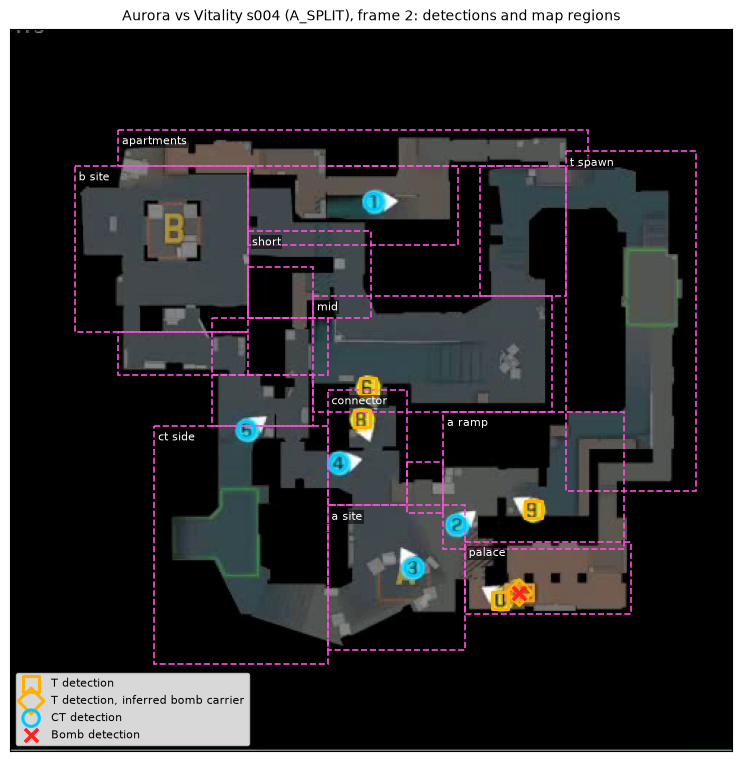

In [11]:
# @title Figure: one radar frame with detections and map regions
E["q22"] = None
row = example_rows.get("A_SPLIT")
cache = data["detections"] / f"{row['clip_id']}.npz" if row and data["detections"] else None
if cache is not None and cache.is_file():
    import cv2
    from stratscout.clip_data import Regions
    from stratscout.tactic_features import DETECTION_VERSION, _digest

    video = row["path"]
    with np.load(cache) as saved:
        if str(saved["version"]) != DETECTION_VERSION or str(saved["digest"]) != _digest(video):
            raise ValueError(f"Saved detections for {row['clip_id']} are from another detector version or clip file")
        players, bomb = saved["players"], saved["bomb"]
    counts = np.bincount(players[:, 0].astype(int), minlength=len(bomb))
    frame = int(np.argmax(np.where(bomb[:, 0] > 0, counts, -1)))  # most players, bomb detected; earliest on ties
    capture = cv2.VideoCapture(str(video))
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame)
    ok, bgr = capture.read()
    capture.release()
    if not ok:
        raise ValueError(f"Cannot read frame {frame} of {video.name}")
    image = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    regions = Regions.load()
    here = players[players[:, 0] == frame]
    fig, ax = plt.subplots(figsize=(7.5, 7.5), layout="constrained")
    ax.imshow(image, extent=[0, 1, 1, 0])
    for name, rects in zip(regions.names, regions.rects):
        for x0, y0, x1, y1 in rects:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#ff4fd8", linewidth=1.2, linestyle="--"))
        x0, y0 = rects[0][:2]
        ax.text(x0 + 0.005, y0 + 0.02, name.replace("_", " "), color="white", fontsize=8, bbox=dict(facecolor="#000000", alpha=0.55, pad=1, edgecolor="none"))
    t = here[(here[:, 3] == 0) & (here[:, 4] == 0)]
    carrier = here[(here[:, 3] == 0) & (here[:, 4] == 1)]
    ct = here[here[:, 3] == 1]
    ax.scatter(t[:, 1], t[:, 2], s=140, facecolor="none", edgecolor="#ffb000", linewidth=2.2, marker="s", label="T detection")
    ax.scatter(carrier[:, 1], carrier[:, 2], s=170, facecolor="none", edgecolor="#ffb000", linewidth=2.2, marker="D", label="T detection, inferred bomb carrier")
    ax.scatter(ct[:, 1], ct[:, 2], s=140, facecolor="none", edgecolor="#00c8ff", linewidth=2.2, marker="o", label="CT detection")
    if bomb[frame, 0] > 0:
        ax.scatter([bomb[frame, 1]], [bomb[frame, 2]], s=90, color="#ff2020", marker="x", linewidth=2.5, label="Bomb detection")
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="lower left", fontsize=8, framealpha=0.85)
    ax.set_title(f"{MATCH_NAMES[row['match']]} {row['clip_id'].split('.')[-1]} ({row['label']}), frame {frame + 1}: detections and map regions", fontsize=10)
    plt.show()
    index = regions.index(here[:, 1:3]) if len(here) else np.zeros(0, int)
    E["q22"] = dict(
        frame=frame, t=len(t) + len(carrier), ct=len(ct), bomb=bool(bomb[frame, 0] > 0), in_region=int((index >= 0).sum()),
        detections=len(here), t_regions=sorted({regions.names[i] for i in index[here[:, 3] == 0] if i >= 0}),
    )
else:
    say(f"{DASH} The training clip or its saved detections are not available (Appendix A5).")

**Answer.** In this frame the detector produced T and CT detections and a bomb detection, and inferred which T carries the bomb. All detections in this frame fall inside a named map region; per-region counts of detections, row by row, are what the shared clip features record. Ts were detected in several regions on the way to A, including connector. These are detections, not game truth.

In [12]:
# @title Key numbers
q = E["q22"]
say(f"Frame {q['frame'] + 1}: {q['t']} T and {q['ct']} CT detections, bomb detected: {'yes' if q['bomb'] else 'no'}; {q['in_region']} of {q['detections']} detections inside a named region." if q else DASH)

Frame 2: 5 T and 5 CT detections, bomb detected: yes; 10 of 10 detections inside a named region.

### 2.3 What do shared clip features look like?

Two training clips at the same site from the same match: the first A_SPLIT and the first A_DIRECT clip (by clip number) of the first development match. In each panel, rows are map regions and columns are time; the colour is the number of Ts the detector placed in that region on that row. The strip below shows the detected bomb state over the same time (dark = on). Before any clip array is opened, the clip-data index is checked to list training clips only.

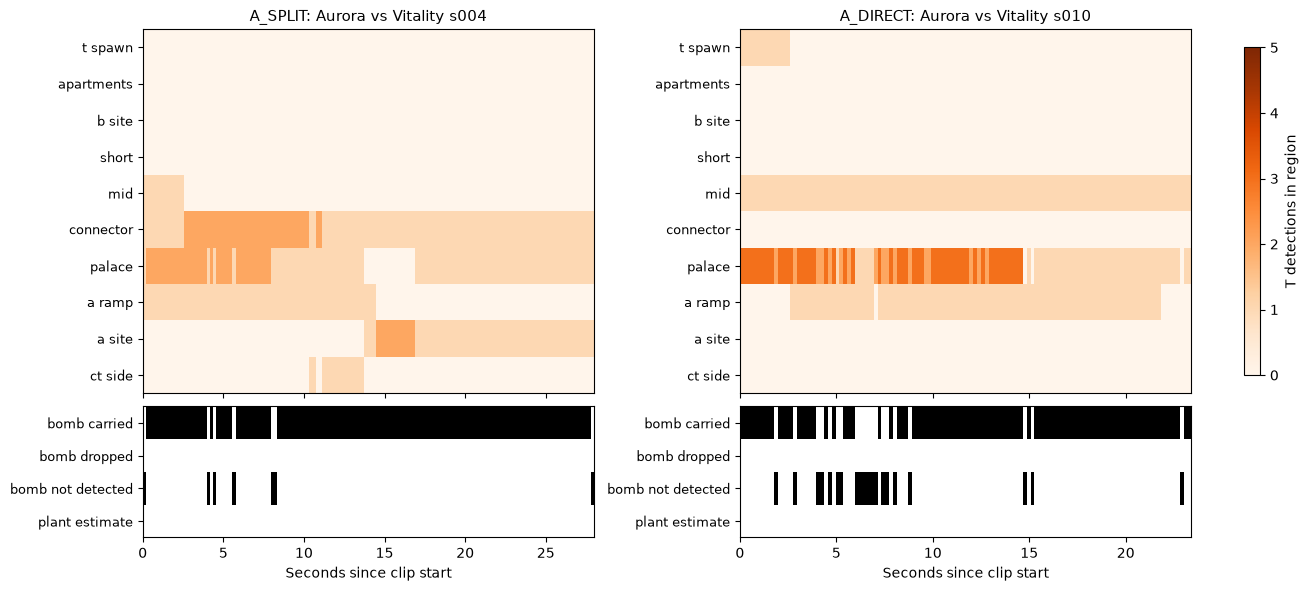

In [13]:
# @title Figure: T detections per region over time, A_SPLIT vs A_DIRECT, with the bomb state
ROUTE = ["t_spawn", "apartments", "b_site", "short", "mid", "connector", "palace", "a_ramp", "a_site", "ct_side"]
BOMB = ["bomb_carried", "bomb_dropped", "bomb_missing", "bomb_planted_est"]
E["q23"] = None
if data["clip_data"] and len(example_rows) == 2 and INCLUDED:
    with (data["clip_data"] / "index.csv").open(encoding="utf-8", newline="") as stream:
        index_rows = list(csv.DictReader(stream))
    bad = [r["clip_id"] for r in index_rows if r.get("split") != "train" or r["clip_id"] not in TRAIN]
    if bad:
        raise ValueError(f"The clip-data index lists {len(bad)} non-training clips; use the train-only copy")
    channels = json.loads((data["clip_data"] / "channels.json").read_text(encoding="utf-8"))["detector"]
    example = {}
    for label in ("A_SPLIT", "A_DIRECT"):
        with np.load(data["clip_data"] / "clips" / f"{example_rows[label]['clip_id']}.npz") as clip:
            x, times = clip["detector"], clip["t_s"]
        example[label] = dict(
            t_players=np.stack([x[:, channels.index(f"t_in_{r}")] * 5 for r in ROUTE]),  # stored as players / 5
            bomb=np.stack([x[:, channels.index(b)] for b in BOMB]),
            times=times,
        )
    fig, axes = plt.subplots(2, 2, figsize=(13, 5.8), layout="constrained", height_ratios=[len(ROUTE), len(BOMB) * 0.9], sharex="col")
    for col, label in enumerate(("A_SPLIT", "A_DIRECT")):
        e, end = example[label], float(example[label]["times"][-1])
        image = axes[0, col].imshow(e["t_players"], aspect="auto", cmap="Oranges", vmin=0, vmax=5, extent=[0, end, len(ROUTE) - 0.5, -0.5], interpolation="nearest")
        axes[0, col].set_yticks(range(len(ROUTE)), [r.replace("_", " ") for r in ROUTE], fontsize=9)
        axes[0, col].set_title(f"{label}: {MATCH_NAMES[EXAMPLE_MATCH]} {example_rows[label]['clip_id'].split('.')[-1]}", fontsize=11)
        axes[1, col].imshow(e["bomb"], aspect="auto", cmap="Greys", vmin=0, vmax=1, extent=[0, end, len(BOMB) - 0.5, -0.5], interpolation="nearest")
        axes[1, col].set_yticks(range(len(BOMB)), ["bomb carried", "bomb dropped", "bomb not detected", "plant estimate"], fontsize=9)
        axes[1, col].set_xlabel("Seconds since clip start")
    fig.colorbar(image, ax=axes[0, :], shrink=0.9, label="T detections in region")
    plt.show()
    E["q23"] = dict(
        share={l: {r: float((e["t_players"][ROUTE.index(r)] > 0).mean()) for r in ROUTE} for l, e in example.items()},
        bomb={l: {b: float(e["bomb"][BOMB.index(b)].mean()) for b in BOMB} for l, e in example.items()},
    )
else:
    say(f"{DASH} The shared clip features of the example clips are not available (Appendix A5).")

**Answer.** In the A_SPLIT clip, a T was detected in connector on every sampled row, and Ts were also detected in palace and ramp. In the A_DIRECT clip no T was detected in connector; Ts were detected in palace and ramp, and in mid on every sampled row. The bomb was detected as carried on most rows of both clips, and the plant estimate stayed off in both examples. Differences like the connector row are what a model must pick up to separate split from direct.

In [14]:
# @title Key numbers
q = E["q23"]
say(f"T detected in connector on {q['share']['A_SPLIT']['connector']:.0%} of A_SPLIT rows and {q['share']['A_DIRECT']['connector']:.0%} of A_DIRECT rows; plant estimate on for {q['bomb']['A_SPLIT']['bomb_planted_est']:.0%} and {q['bomb']['A_DIRECT']['bomb_planted_est']:.0%} of rows." if q else DASH)

T detected in connector on 100% of A_SPLIT rows and 0% of A_DIRECT rows; plant estimate on for 0% and 0% of rows.

### 2.4 How is a model scored?

The table lists the evaluation design and why each choice was made. Nested epoch selection means the number of training epochs for a held-out match is chosen using only its training matches; the check below reads the inner folds each saved fit actually used.

In [15]:
# @title Table: design decisions
n_matches = len(reference)
say(
    "| Decision | Choice | Why |\n|:---|:---|:---|\n"
    f"| Image features | Frozen ImageNet ResNet-18 | Freezing limits the parameters learned from {N_CLIPS} clips to the small classifier on top. |\n"
    "| Player positions | Rule-based minimap icon detector | There are no labelled positions to train a detector on; its detections were checked against the positions recorded in the match demos ([detector check](../docs/detector-check.md)). |\n"
    f"| Data split | Leave one match out ({n_matches} folds) | Clips from one match are correlated (same teams, same recording), so they must not be split between training and scoring. |\n"
    "| Epoch choice | Nested epoch selection | The scored match never influences the number of training epochs. |\n"
    f"| Training noise | {N_SEEDS} seeds per held-out match | Shows how much a score moves with the seed alone: the starting weights and, depending on the model, dropout, mini-batch order and augmentation. |\n"
    "| Main score | Macro-F1 | Classes are uneven; every tactic counts equally (1.3). |\n"
    "| Loss | Class-weighted cross-entropy | Weighting increases rare classes' contribution to the loss (3.5). |"
)
nested_fits = list({r["source"]: r for k, r in everything if k[2] == "nested"}.items())  # each saved run once
inner = [v for _, r in nested_fits for v in (r["inner"] or [None])]
E["q24"] = dict(inner=None if any(v is None for v in inner) else inner, fits=len(inner), results=len(nested_fits))

| Decision | Choice | Why |
|:---|:---|:---|
| Image features | Frozen ImageNet ResNet-18 | Freezing limits the parameters learned from 82 clips to the small classifier on top. |
| Player positions | Rule-based minimap icon detector | There are no labelled positions to train a detector on; its detections were checked against the positions recorded in the match demos ([detector check](../docs/detector-check.md)). |
| Data split | Leave one match out (4 folds) | Clips from one match are correlated (same teams, same recording), so they must not be split between training and scoring. |
| Epoch choice | Nested epoch selection | The scored match never influences the number of training epochs. |
| Training noise | 3 seeds per held-out match | Shows how much a score moves with the seed alone: the starting weights and, depending on the model, dropout, mini-batch order and augmentation. |
| Main score | Macro-F1 | Classes are uneven; every tactic counts equally (1.3). |
| Loss | Class-weighted cross-entropy | Weighting increases rare classes' contribution to the loss (3.5). |

**Answer.** Each development match is held out in turn: the model trains on the other matches and is scored once on the held-out one. For every nested fit, the epoch count was chosen on inner folds that leave out each training match in turn and never include the held-out match. Every fit is repeated with several seeds, which change the starting weights and, depending on the model, dropout, mini-batch order and augmentation. A model's score is the mean macro-F1 over held-out matches and seeds; ± is the SD over seeds of each seed's mean.

In [16]:
# @title Key numbers
q = E["q24"]
say(f"{len(reference)} held-out matches × {N_SEEDS} seeds; " + (f"the inner folds exclude the held-out match in all {q['fits']} nested fits of {q['results']} results." if q["inner"] else "inner-fold records missing."))

4 held-out matches × 3 seeds; the inner folds exclude the held-out match in all 128 nested fits of 12 results.

## 3. Model development and training

### 3.1 How were the models trained, and why?

One row per training choice: what it does, why it is used here, its setting for each setup (read from the saved run configurations; loss and optimiser types from the code, linked), and the evidence in this report. Only class weighting was tested on its own; the full settings table is in Appendix A3.

In [17]:
# @title Table: training choices
temporal = results[("Compact pooled GRU", "Shared clip features", "nested")]["config"]
s31, gru31 = temporal["settings"], temporal["temporal"]
tcn31 = results[("TCN", "Shared clip features", "nested")]["config"]
det31 = results[("TCN", "Detector features", "other-folds")]["config"] if ("TCN", "Detector features", "other-folds") in results else None
standard = "Not tested separately (standard practice)"
say(
    "| Training choice | What it does | Why it is used here | Pooling models and Compact pooled GRU | TCN and pooled classifier | Evidence |\n"
    "|:---|:---|:---|:---|:---|:---|\n"
    "| Class-weighted cross-entropy ([pooling, GRU](../stratscout/tactic_training.py#L191); [TCN](../stratscout/tactic_tcn.py#L243)) | Weights each class's errors by the inverse of its share of the training clips | Weighting increases rare classes' contribution to the loss | on (every model in the main comparison) | on | Tested: 3.5 |\n"
    f"| Label smoothing | Makes the training targets slightly soft | Intended to discourage over-confident outputs | none | {tcn31['label_smoothing']} | {standard} |\n"
    f"| AdamW with weight decay ([pooling, GRU](../stratscout/tactic_training.py#L188); [TCN](../stratscout/tactic_tcn.py#L237)) | Adaptive step size per weight; weight decay shrinks weights at every step | Intended to keep weights small with few clips | learning rate {s31['learning_rate']}, weight decay {s31['weight_decay']}, full batch | learning rate {tcn31['lr']}, weight decay {tcn31['weight_decay']}, batch {tcn31['batch']} | {standard} |\n"
    f"| Warm-up | The learning rate rises linearly over the first epochs, then stays constant | Intended to avoid large early updates on mini-batches | none | {tcn31['warmup_epochs']} epochs | {standard} |\n"
    f"| Dropout | Randomly silences parts of the network during training | Intended to reduce reliance on a few memorised features | Compact pooled GRU {gru31['dropout']}; pooling models none | {tcn31['dropout']} | Shown in 3.2, 3.3; size and dropout changed together, individual effect unmeasured |\n"
    f"| Epoch choice by nested selection (early stopping) | Stops at the epoch that was best on the training matches, then refits to it | Avoids too few or too many epochs without using the scored match | up to {s31['epochs']}, stop after {s31['patience']} without gain | up to {tcn31['epochs']}, checked every {tcn31['eval_every']} | Shown in 3.3, A1 |\n"
    "| Frozen ResNet-18 | Keeps the ImageNet weights fixed; only the classifier learns | Far fewer weights to learn from few clips | frozen | frozen (inside shared clip features) | " + standard + " |\n"
    + (f"| Detector-error augmentation | Jitters training positions and drops some detections | Intended to make the model robust to detector mistakes | none | detector-features TCN and its pooled control: jitter {det31['jitter']}, {det31['drop']:.0%} dropped; shared clip features: none | {standard} |\n" if det31 else "")
)
main_runs = [r for (m, i, rule), r in results.items() if "settings" in r["config"]]
E["q31"] = dict(weighted=sum(r["config"]["settings"].get("class_weights", True) for r in main_runs), runs=len(main_runs), tcn_input=tcn31["input"], det_input=det31["input"] if det31 else None)

| Training choice | What it does | Why it is used here | Pooling models and Compact pooled GRU | TCN and pooled classifier | Evidence |
|:---|:---|:---|:---|:---|:---|
| Class-weighted cross-entropy ([pooling, GRU](../stratscout/tactic_training.py#L191); [TCN](../stratscout/tactic_tcn.py#L243)) | Weights each class's errors by the inverse of its share of the training clips | Weighting increases rare classes' contribution to the loss | on (every model in the main comparison) | on | Tested: 3.5 |
| Label smoothing | Makes the training targets slightly soft | Intended to discourage over-confident outputs | none | 0.05 | Not tested separately (standard practice) |
| AdamW with weight decay ([pooling, GRU](../stratscout/tactic_training.py#L188); [TCN](../stratscout/tactic_tcn.py#L237)) | Adaptive step size per weight; weight decay shrinks weights at every step | Intended to keep weights small with few clips | learning rate 0.01, weight decay 0.001, full batch | learning rate 0.001, weight decay 0.01, batch 8 | Not tested separately (standard practice) |
| Warm-up | The learning rate rises linearly over the first epochs, then stays constant | Intended to avoid large early updates on mini-batches | none | 5 epochs | Not tested separately (standard practice) |
| Dropout | Randomly silences parts of the network during training | Intended to reduce reliance on a few memorised features | Compact pooled GRU 0.3; pooling models none | 0.2 | Shown in 3.2, 3.3; size and dropout changed together, individual effect unmeasured |
| Epoch choice by nested selection (early stopping) | Stops at the epoch that was best on the training matches, then refits to it | Avoids too few or too many epochs without using the scored match | up to 200, stop after 30 without gain | up to 150, checked every 10 | Shown in 3.3, A1 |
| Frozen ResNet-18 | Keeps the ImageNet weights fixed; only the classifier learns | Far fewer weights to learn from few clips | frozen | frozen (inside shared clip features) | Not tested separately (standard practice) |
| Detector-error augmentation | Jitters training positions and drops some detections | Intended to make the model robust to detector mistakes | none | detector-features TCN and its pooled control: jitter 0.005, 5% dropped; shared clip features: none | Not tested separately (standard practice) |


**Answer.** The **loss** measures how wrong the model is on each training clip: it is small when the model gives the true class a high probability and grows quickly when it is confidently wrong. Class weights make a mistake on a rare class cost more, which increases that class's contribution to the loss. Label smoothing (TCN) is intended to stop probabilities being pushed all the way to certainty. The **optimiser** then nudges every weight a little in the direction that lowers the loss. AdamW scales each step by how consistent that weight's recent gradients were, and weight decay shrinks weights slightly at every step. Training repeats this pass by pass, and nested selection decides when to stop, using only the training matches. Of these choices, only class weighting was tested on its own.

In [18]:
# @title Key numbers
q = E["q31"]
say(f"Class weights on in {q['weighted']} of {q['runs']} pooling and GRU runs of the main comparison (TCN: always, from the code); augmentation only with detector features.")

Class weights on in 12 of 12 pooling and GRU runs of the main comparison (TCN: always, from the code); augmentation only with detector features.

### 3.2 Which GRU design works best?

A GRU updates a memory as it reads each frame. Three designs were tried on ResNet images, each fixed before its score was seen. The table says what changed from one design to the next and gives each design's nested macro-F1; sizes and parameter counts are in Appendix A4.

In [19]:
# @title Table: the three GRU designs
designs = {v: gru_versions[v]["nested"] for v in GRU_NAMES}
E["q32"] = designs if all(designs.values()) else None
changed = {
    "laststate": "Starting design; the classifier reads the final memory",
    "compact_laststate": "Smaller network with dropout; the classifier still reads the final memory",
    "compact_pooled": "Same compact network; the classifier reads the average and maximum memory values across frames",
}
show_table("gru-designs", pd.DataFrame([[GRU_NAMES[v], changed[v], fmt(designs[v])] for v in GRU_NAMES], columns=["GRU design", "What changed", "Nested macro-F1"]))

GRU design,What changed,Nested macro-F1
Last-state GRU,Starting design; the classifier reads the final memory,0.345 ± 0.008
Compact last-state GRU,Smaller network with dropout; the classifier still reads the final memory,0.327 ± 0.004
Compact pooled GRU,Same compact network; the classifier reads the average and maximum memory values across frames,0.600 ± 0.028


**Answer.** The Last-state GRU classified each clip from its final memory. Making the network compact and adding dropout (Compact last-state GRU) did not help: the score moved slightly down. Keeping that compact network but letting the classifier read the average and maximum of each memory value across all real frames (Compact pooled GRU) raised the score by far the most. We therefore selected the pooled readout; the Compact pooled GRU is the GRU compared in section 4.

In [20]:
# @title Key numbers
q = E["q32"]
say(", ".join(f"{GRU_NAMES[v]} {q[v]['mean']:.3f}" for v in GRU_NAMES) + " (nested macro-F1)." if q else DASH)

Last-state GRU 0.345, Compact last-state GRU 0.327, Compact pooled GRU 0.600 (nested macro-F1).

### 3.3 Do the models overfit?

Learning curves for the Last-state GRU and the Compact pooled GRU (ResNet images) and the TCN (shared clip features), all for the same held-out match and seed (Spirit vs Falcons, seed 0). The GRU curves come from diagnostic fits that were scored on the held-out match after every epoch; they did not choose the reported epoch. The TCN curve comes from one extra run of the same fit ([scripts/tcn_curves.py](../scripts/tcn_curves.py)), checked to reproduce the nested run's predictions at its chosen epoch. Training loss is class-weighted (TCN: also label-smoothed) and validation loss isn't, so compare trends, not the gap. The dotted line is the epoch nested selection chose from the training matches; the dot marks the lowest validation loss. The verdicts use thresholds defined in the notebook and printed under the answer.

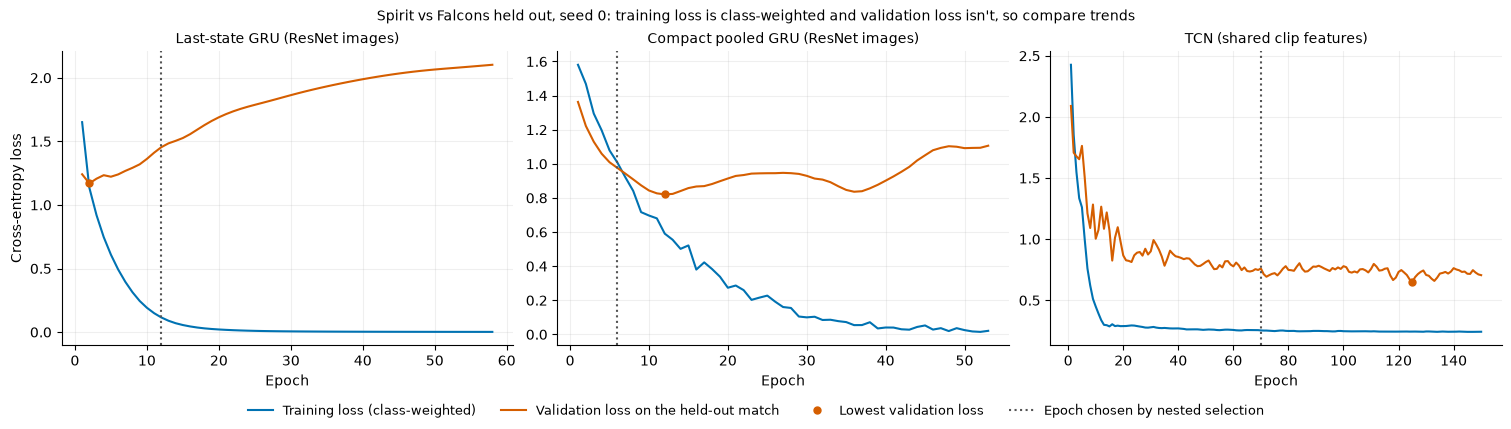

In [21]:
# @title Figure: learning curves on one held-out match and seed
CURVE_FOLD, CURVE_SEED = 1, 0  # the first held-out match and the first seed
OVERFIT_RISE = 0.10  # validation loss ends at least this far above its minimum (relative)...
MILD_SHARE = 0.5  # ...and "mild" when that rise is under this share of the Last-state GRU's


def gru_curve(version, fold=CURVE_FOLD, seed=CURVE_SEED):
    folder = runs.get(GRU_VERSIONS[version][0])
    path = folder / "gru" / f"fold-{fold}-seed-{seed}-optimistic-history.json" if folder else None
    if path is None or not path.is_file():
        return None
    history = json.loads(path.read_text(encoding="utf-8"))
    fold_json = json.loads((folder / "gru" / f"fold-{fold}.json").read_text(encoding="utf-8"))
    return dict(
        train=np.array([h["train_loss"] for h in history]), val=np.array([h["validation_loss"] for h in history]),
        chosen=next(r["evaluation_epoch"] for r in fold_json["runs"] if r["seed"] == seed),
        match=match_of(fold_json["validation_clip_ids"][0]), seed=seed,
    )


def describe(c):
    low = int(c["val"].argmin())
    c.update(low_epoch=low + 1, low=c["val"][low], end=c["val"][-1], end_epoch=len(c["val"]), train_at_low=c["train"][low], train_end=c["train"][-1])
    c["rise"] = (c["end"] - c["low"]) / c["low"]  # relative rise of validation loss after its minimum
    c["train_fell"] = c["train_end"] < c["train_at_low"] - 0.01
    return c


curves = {"Last-state GRU": gru_curve("laststate"), "Compact pooled GRU": gru_curve("compact_pooled")}
if tcn_curves:
    h = tcn_curves["history"]
    curves["TCN"] = dict(
        train=np.array([e["train_loss"] for e in h]), val=np.array([e["validation_loss"] for e in h]),
        chosen=tcn_curves["chosen_epoch"], match=tcn_curves["held_out"], seed=tcn_curves["seed"],
    )
curves = {k: describe(c) for k, c in curves.items() if c is not None}
reference_rise = curves["Last-state GRU"]["rise"] if "Last-state GRU" in curves else None
for c in curves.values():
    if c["train_fell"] and c["rise"] >= OVERFIT_RISE:
        c["verdict"] = "mild overfitting" if reference_rise and c["rise"] < MILD_SHARE * reference_rise else "overfitting"
    else:
        c["verdict"] = "no clear overfitting"
inputs_of = {"Last-state GRU": "ResNet images", "Compact pooled GRU": "ResNet images", "TCN": "shared clip features"}
fig, axes = plt.subplots(1, len(curves), figsize=(5 * len(curves), 4.2), layout="constrained")
for ax, (name, c) in zip(np.atleast_1d(axes), curves.items()):
    epochs = np.arange(1, len(c["val"]) + 1)
    ax.plot(epochs, c["train"], color="#0072B2", label="Training loss (class-weighted)")
    ax.plot(epochs, c["val"], color="#D55E00", label="Validation loss on the held-out match")
    ax.plot(c["low_epoch"], c["low"], "o", color="#D55E00", markersize=5, label="Lowest validation loss")
    ax.axvline(c["chosen"], color="#555555", linestyle=":", label="Epoch chosen by nested selection")
    ax.set_title(f"{name} ({inputs_of[name]})", fontsize=10)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel("Cross-entropy loss")
fig.legend(*np.atleast_1d(axes)[0].get_legend_handles_labels(), loc="outside lower center", ncol=4, fontsize=9, frameon=False)
first = next(iter(curves.values()))
fig.suptitle(f"{MATCH_NAMES[first['match']]} held out, seed {first['seed']}: training loss is class-weighted and validation loss isn't, so compare trends", fontsize=10)
plt.show()
# Every held-out match and seed for the GRUs, over the epochs all their curves share.
every = {v: [gru_curve(v, f, s) for f in range(1, len(MATCHES) + 1) for s in range(N_SEEDS)] for v in GRU_VERSIONS}
every = {v: cs for v, cs in every.items() if all(cs)}
common = min(len(c["val"]) for cs in every.values() for c in cs)
E["q33"] = dict(curves=curves, rise={v: float(np.mean([c["val"][:common][-1] - c["val"][:common].min() for c in cs])) for v, cs in every.items()}, common=common, n=len(every.get("laststate", [])))

**Answer.** The Last-state GRU overfits: its training loss falls almost to zero while its validation loss climbs far above its lowest point. The Compact pooled GRU shows mild overfitting: validation loss also rises after its minimum, but much less, and across every held-out match and seed its average rise is a small fraction of the Last-state GRU's. On this held-out match and seed (Spirit vs Falcons, seed 0), the TCN shows no clear overfitting: its training loss levels off (label smoothing keeps it above zero) and its validation loss stays close to its minimum. "Overfitting", "mild" and "no clear" use the thresholds defined in the notebook (printed below). The epochs actually used (dotted lines) need not sit at the lowest validation loss, because they were chosen by macro-F1 on the training matches, not from the curves shown.

In [22]:
# @title Key numbers
q = E["q33"]
say("; ".join(f"{n}: {c['verdict']} (validation loss {c['rise']:+.0%} from its minimum)" for n, c in q["curves"].items())
    + f". Thresholds: overfitting when training loss keeps falling after the validation minimum and validation loss ends at least {OVERFIT_RISE:.0%} above it; mild when that rise is under {MILD_SHARE:.0%} of the Last-state GRU's.")

Last-state GRU: overfitting (validation loss +80% from its minimum); Compact pooled GRU: mild overfitting (validation loss +35% from its minimum); TCN: no clear overfitting (validation loss +8% from its minimum). Thresholds: overfitting when training loss keeps falling after the validation minimum and validation loss ends at least 10% above it; mild when that rise is under 50% of the Last-state GRU's.

### 3.4 Does time order matter?

Temporal average pooling averages the early, middle and late third of a clip separately. The random-segment control uses the same three segments and classifier, but puts each clip's frames into the segments at random, which removes the time order (ResNet images, nested). If order matters, temporal average pooling should score higher.

In [23]:
# @title Table: temporal average pooling vs the random-segment control
thirds34 = results.get(("Temporal average pooling (3 segments)", "ResNet images", "nested"))
E["q34"] = None
if thirds34 and random_segments:
    keys34 = sorted(thirds34["pairs"])
    E["q34"] = dict(diff=thirds34["mean"] - random_segments["mean"], sd=max(thirds34["sd"], random_segments["sd"]), ahead=sum(thirds34["pairs"][k] > random_segments["pairs"][k] for k in keys34), pairs=len(keys34))
    show_table("thirds-vs-random-segments", pd.DataFrame([["Temporal average pooling (3 segments)", fmt(thirds34)], ["Random-segment control", fmt(random_segments)]], columns=["Model (ResNet images)", "Nested macro-F1"]))
else:
    say(f"{DASH} Temporal average pooling or the random-segment control was not found.")

Model (ResNet images),Nested macro-F1
Temporal average pooling (3 segments),0.620 ± 0.015
Random-segment control,0.526 ± 0.012


**Answer.** Yes, on these development matches. Keeping the frames in time order scored clearly higher than putting them into the same segments at random, in almost every match-and-seed pair.

In [24]:
# @title Key numbers
q = E["q34"]
say(f"Difference {q['diff']:+.3f}; ahead in {q['ahead']} of {q['pairs']} match-and-seed pairs." if q else DASH)

Difference +0.094; ahead in 11 of 12 match-and-seed pairs.

### 3.5 What do class weights change?

Temporal average pooling on ResNet images was rerun once with class weights off (nested, same folds and seeds). The table gives nested macro-F1 and, per class, the F1 on pooled seed-ensemble predictions (as in 4.5); the figure puts the per-class F1 with and without weights side by side.

Class weights,Nested macro-F1,A_DIRECT F1,B_DIRECT F1,A_SPLIT F1,B_SPLIT F1,RETAKE F1,Pooled macro-F1
On (default),0.620 ± 0.015,0.595,0.727,0.500,0.600,0.821,0.648
Off,0.564 ± 0.005,0.579,0.784,0.381,0.667,0.821,0.646


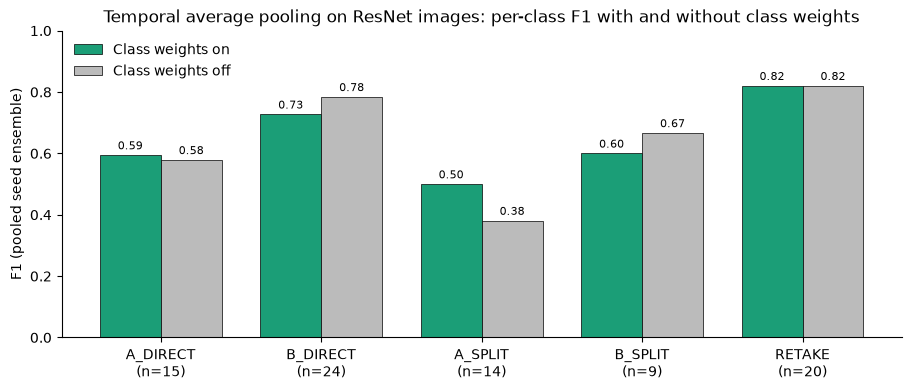

In [25]:
# @title Table and figure: class weights on vs off
weighted = results.get(("Temporal average pooling (3 segments)", "ResNet images", "nested"))
E["q35"] = None
if weighted and unweighted:
    show_table("class-weights", 
        pd.DataFrame(
            [
                ["On (default)", fmt(weighted)] + [weighted["pooled_f1"][c] for c in CLASSES] + [weighted["pooled_macro"]],
                ["Off", fmt(unweighted)] + [unweighted["pooled_f1"][c] for c in CLASSES] + [unweighted["pooled_macro"]],
            ],
            columns=["Class weights", "Nested macro-F1"] + [f"{c} F1" for c in CLASSES] + ["Pooled macro-F1"],
        )
    )
    fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
    x = np.arange(len(CLASSES))
    for k, (name, r, colour) in enumerate((("Class weights on", weighted, "#1b9e77"), ("Class weights off", unweighted, "#bbbbbb"))):
        values = [r["pooled_f1"][c] for c in CLASSES]
        ax.bar(x + (k - 0.5) * 0.38, values, 0.38, color=colour, edgecolor="black", linewidth=0.5, label=name)
        for xi, v in zip(x, values):
            ax.text(xi + (k - 0.5) * 0.38, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, [f"{c}\n(n={totals[c]})" for c in CLASSES])
    ax.set_ylim(0, 1)
    ax.set_ylabel("F1 (pooled seed ensemble)")
    ax.set_title("Temporal average pooling on ResNet images: per-class F1 with and without class weights")
    ax.legend(frameon=False, loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()
    E["q35"] = dict(
        diff=unweighted["mean"] - weighted["mean"], sd=max(weighted["sd"], unweighted["sd"]),
        deltas={c: unweighted["pooled_f1"][c] - weighted["pooled_f1"][c] for c in CLASSES},
        pooled=(weighted["pooled_macro"], unweighted["pooled_macro"]), nested=(fmt(weighted), fmt(unweighted)),
    )
else:
    say(f"{DASH} The weighted or unweighted run was not found (Appendix A5).")

**Answer.** Turning class weights off lowered nested macro-F1, by more than the seed spread. Per class, A_SPLIT lost the most and A_DIRECT a little; B_DIRECT, the largest class, gained, and so did B_SPLIT; RETAKE was unchanged. On the pooled seed-ensemble predictions the macro-F1 barely moves, so the drop shows in the per-match, per-seed scores rather than in the ensemble. Weighting was used because the classes are uneven: it increases rare classes' contribution to the loss, which otherwise counts every clip the same.

In [26]:
# @title Key numbers
q = E["q35"]
say(f"Nested macro-F1 {q['diff']:+.3f} without weights; pooled macro-F1 {q['pooled'][1] - q['pooled'][0]:+.3f}; largest per-class change A_SPLIT {q['deltas']['A_SPLIT']:+.3f}." if q else DASH)

Nested macro-F1 -0.056 without weights; pooled macro-F1 -0.002; largest per-class change A_SPLIT -0.119.

## 4. Model comparison

ResNet-18 was trained to recognise objects in photos, so its features describe how the minimap looks, not where each player is. Tactics depend on who goes where, and when. Shared clip features keep a few compressed ResNet components and add the detector's information: detections per map region, which regions Ts have been detected in, the detected bomb state and elapsed time. ResNet images alone remain the baseline input. The two inputs are also sampled differently (a fixed number of frames per clip vs rows at a fixed rate), so input comparisons include that change. Every score in this section uses nested epoch selection on the same clips, held-out matches and seeds.

### 4.1 Selected configurations with completed nested runs: which scores highest?

Each bar is one selected configuration (model and input) with a completed nested run, sorted from best to worst; colour shows the input. The black line is ± the seed SD, the open dots are the scores on the individual held-out matches, and the dashed line is the majority-class baseline (always answering each fold's largest training class). Value labels sit past the bar ends. The table below gives every model on every input; a dash means no completed nested run.

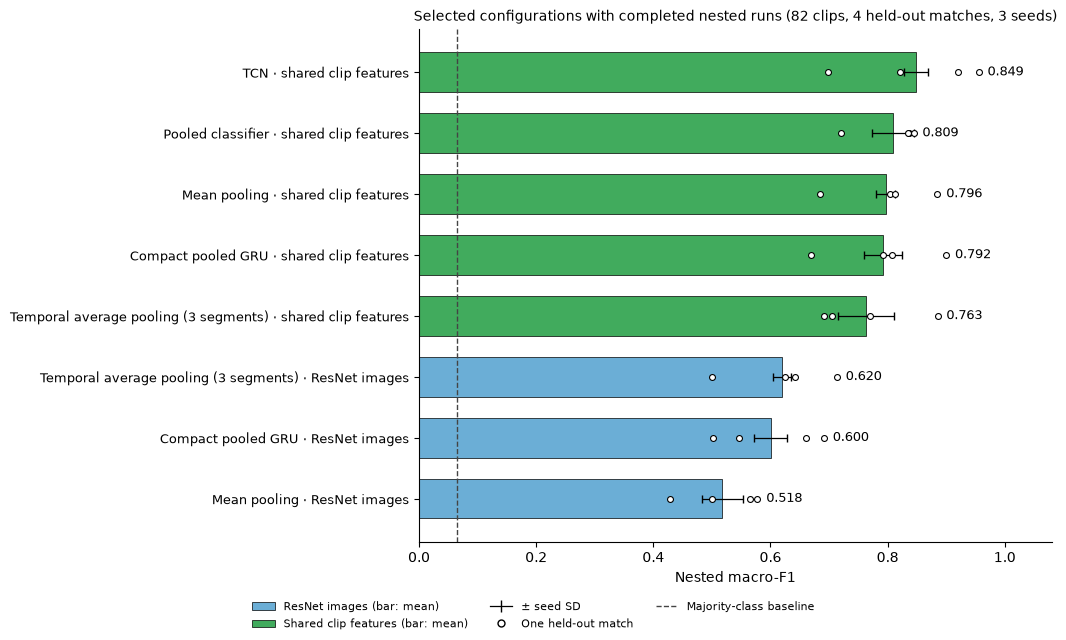

Model (nested macro-F1),ResNet images,Detector features,Shared clip features
Mean pooling,0.518 ± 0.034,—,0.796 ± 0.016
Temporal average pooling (3 segments),0.620 ± 0.015,—,0.763 ± 0.048
Compact pooled GRU,0.600 ± 0.028,—,0.792 ± 0.033
TCN,—,—,0.849 ± 0.021
Pooled classifier,—,—,0.809 ± 0.035


In [27]:
# @title Figure and table: selected configurations with completed nested runs, ranked
ranked = sorted(nested, key=lambda k: nested[k]["mean"])  # worst first, drawn at the bottom
fig, ax = plt.subplots(figsize=(10.5, 0.55 * len(ranked) + 1.9), layout="constrained")
for y, k in enumerate(ranked):
    r = nested[k]
    ax.barh(y, r["mean"], 0.65, color=COLOURS[k[1]], edgecolor="black", linewidth=0.5)
    ax.errorbar(r["mean"], y, xerr=r["sd"], color="black", linewidth=0.9, capsize=3)
    ax.scatter(list(r["per_match"].values()), [y] * len(r["per_match"]), s=18, facecolor="white", edgecolor="black", linewidth=0.8, zorder=3)
    ax.text(max(r["mean"] + r["sd"], max(r["per_match"].values())) + 0.015, y, f"{r['mean']:.3f}", va="center", ha="left", fontsize=9)
if majority:
    ax.axvline(majority["macro_f1"], color="#444444", linestyle="--", linewidth=1)
ax.set_yticks(range(len(ranked)), [f"{m} · {inp(i)}" for m, i in ranked], fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("Nested macro-F1")
shown_inputs = [i for i in INPUTS if any(k[1] == i for k in ranked)]
handles = [Patch(facecolor=COLOURS[i], edgecolor="black", linewidth=0.5, label=f"{i} (bar: mean)") for i in shown_inputs]
handles += [
    Line2D([], [], color="black", linewidth=0.9, marker="|", markersize=8, label="± seed SD"),
    Line2D([], [], linestyle="none", marker="o", markersize=5, markerfacecolor="white", markeredgecolor="black", label="One held-out match"),
]
if majority:
    handles.append(Line2D([], [], color="#444444", linestyle="--", linewidth=1, label="Majority-class baseline"))
fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False, fontsize=8)
ax.set_title(f"Selected configurations with completed nested runs ({N_CLIPS} clips, {len(reference)} held-out matches, {N_SEEDS} seeds)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
show_table("nested-ranking", pd.DataFrame([[m] + [fmt(nested.get((m, i))) for i in INPUTS] for m in MODELS], columns=["Model (nested macro-F1)"] + INPUTS))
E["q41"] = dict(ranked=list(reversed(ranked)), image=[nested[k]["mean"] for k in nested if k[1] == "ResNet images"], clip=[nested[k]["mean"] for k in nested if k[1] == "Shared clip features"])

**Answer.** The TCN on shared clip features ranks first. Every configuration on shared clip features scores above every configuration on ResNet images; that gap includes the change from sampled frames to rows at a fixed rate as well as the richer input. Every completed run is far above the majority-class baseline. The detector-features TCN and pooled classifier have no completed nested run (only other-folds runs, Appendix A1), so they are not ranked here.

In [28]:
# @title Key numbers
q = E["q41"]
top = q["ranked"][0]
say(f"Top: {top[0]} · {inp(top[1])} {fmt(nested[top])}; lowest shared-clip-feature run {min(q['clip']):.3f} vs highest ResNet-image run {max(q['image']):.3f}" + (f"; baseline {majority['macro_f1']:.3f}." if majority else "."))

Top: TCN · shared clip features 0.849 ± 0.021; lowest shared-clip-feature run 0.763 vs highest ResNet-image run 0.620; baseline 0.065.

### 4.2 Same model, different input: what changes?

Each model is shown with a bar for ResNet images and a bar for shared clip features (± seed SD); "not run" marks a missing nested run. The input change also changes sampling: image models see a fixed number of evenly spaced frames per clip, while shared clip features have rows at a fixed rate.

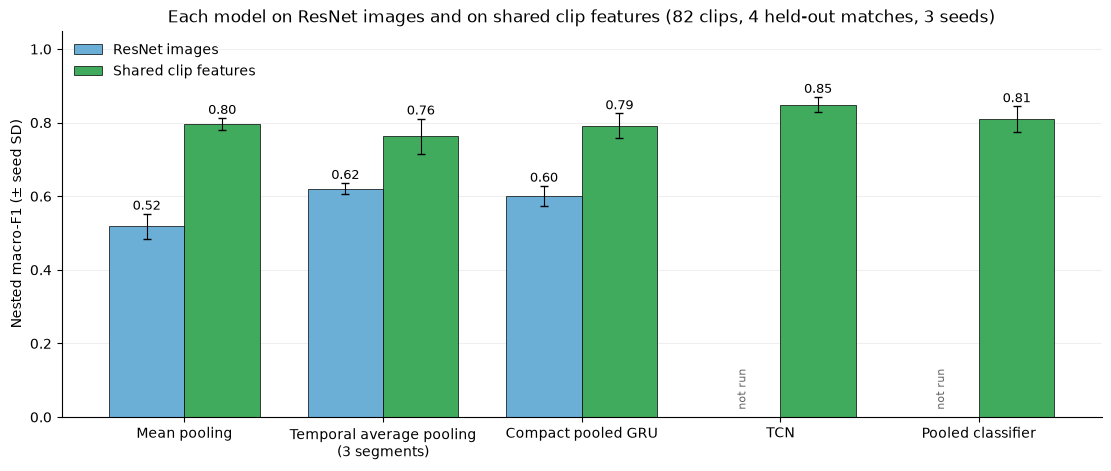

In [29]:
# @title Figure: each model on ResNet images and on shared clip features
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
pair = ("ResNet images", "Shared clip features")
x = np.arange(len(MODELS))
for k, inputs in enumerate(pair):
    for xi, m in zip(x, MODELS):
        pos = xi + (k - 0.5) * 0.38
        r = nested.get((m, inputs))
        if r is None:
            ax.text(pos, 0.02, "not run", ha="center", va="bottom", fontsize=8, color="#666666", rotation=90)
            continue
        ax.bar(pos, r["mean"], 0.38, color=COLOURS[inputs], edgecolor="black", linewidth=0.5, label=inputs if xi == 0 else None)
        ax.errorbar(pos, r["mean"], yerr=r["sd"], color="black", linewidth=0.8, capsize=3)
        ax.annotate(f"{r['mean']:.2f}", (pos, r["mean"] + r["sd"]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x, [m.replace(" (3 segments)", "\n(3 segments)") for m in MODELS])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Nested macro-F1 (± seed SD)")
ax.set_title(f"Each model on ResNet images and on shared clip features ({N_CLIPS} clips, {len(reference)} held-out matches, {N_SEEDS} seeds)")
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Answer.** Every model run on both inputs scored much higher with shared clip features, and each gain is well above the seed spread. The gains include the change in sampling (from frames per clip to rows at a fixed rate) as well as the richer input, so they cannot be credited to the features alone.

In [30]:
# @title Key numbers
say("; ".join(f"{m} {changes[m]:+.3f}" for m in both) + f" ({n_frames} frames per clip → {rate:.0f} rows per second).")

Mean pooling +0.278; Temporal average pooling (3 segments) +0.143; Compact pooled GRU +0.192 (16 frames per clip → 5 rows per second).

### 4.3 Same input, different model: the TCN against its pooled control

On shared clip features, the TCN is compared with its pooled control. The control gets the same rows but averages and max-pools them over the clip before a small network, so the order of rows cannot matter; it still receives elapsed time and route-history features (which map regions Ts have been detected in so far). The two models also differ in architecture and size, so the comparison changes capacity as well as access to row order. The table gives both per held-out match, with each model's number of trainable weights.

In [31]:
# @title Table: TCN vs pooled classifier on shared clip features, per held-out match
tcn43, control43 = nested.get(("TCN", "Shared clip features")), nested.get(("Pooled classifier", "Shared clip features"))
E["q43"] = None
if tcn43 and control43:
    from stratscout.tactic_tcn import TacticConfig, build_model

    cfg43 = TacticConfig(**{k: tuple(v) if isinstance(v, list) else v for k, v in tcn43["config"].items()})
    width43 = detector_channels + pcs
    weights43 = {kind: sum(p.numel() for p in build_model(kind, width43, cfg43).parameters()) for kind in ("tcn", "control")}  # built, not trained
    show_table("tcn-vs-pooled-per-match", 
        pd.DataFrame(
            [[MATCH_NAMES[m], tcn43["per_match"][m], control43["per_match"][m], tcn43["per_match"][m] - control43["per_match"][m]] for m in MATCHES]
            + [["All held-out matches (± seed SD)", fmt(tcn43), fmt(control43), tcn43["mean"] - control43["mean"]]],
            columns=["Held-out match", "TCN", "Pooled classifier", "TCN − pooled"],
        )
    )
    route = None
    if data["clip_data"]:
        names = json.loads((data["clip_data"] / "channels.json").read_text(encoding="utf-8"))["detector"]
        route = ("t_clip" in names, sum(n.startswith("t_reached_") for n in names))
    E["q43"] = dict(
        gap=tcn43["mean"] - control43["mean"], sd=max(tcn43["sd"], control43["sd"]), weights=weights43, route=route,
        leads=[m for m in MATCHES if tcn43["per_match"][m] > control43["per_match"][m]],
    )
else:
    say(f"{DASH} The TCN or its pooled control has no completed nested run.")

Held-out match,TCN,Pooled classifier,TCN − pooled
Spirit vs Falcons,0.699,0.720,-0.021
Furia vs Falcons,0.920,0.834,0.086
MOUZ vs BetBoom,0.822,0.844,-0.022
Aurora vs Vitality,0.955,0.837,0.119
All held-out matches (± seed SD),0.849 ± 0.021,0.809 ± 0.035,0.040


**Answer.** The TCN outscored its pooled control on average and led on half of the held-out matches, with a gap about the size of the larger seed SD (exact numbers below). Because the two models also differ in architecture and capacity, and the control already sees elapsed time and route history, this gap is not a clean measure of what row order adds; on four matches the advantage is small and not consistent.

In [32]:
# @title Key numbers
q = E["q43"]
say(f"The TCN outscored its pooled control by {q['gap']:+.3f} on average and led on {len(q['leads'])} of {len(MATCHES)} matches; trainable weights: TCN {q['weights']['tcn']:,}, pooled classifier {q['weights']['control']:,}." if q else DASH)

The TCN outscored its pooled control by +0.040 on average and led on 2 of 4 matches; trainable weights: TCN 35,365, pooled classifier 6,853.

### 4.4 Does the result hold on every match?

Each cell is one model's nested macro-F1 on one held-out match (mean over seeds), for ResNet images and shared clip features. Matches are named by their first team. Look for whether the same match is hard for every model, and whether shared clip features stay ahead on every match.

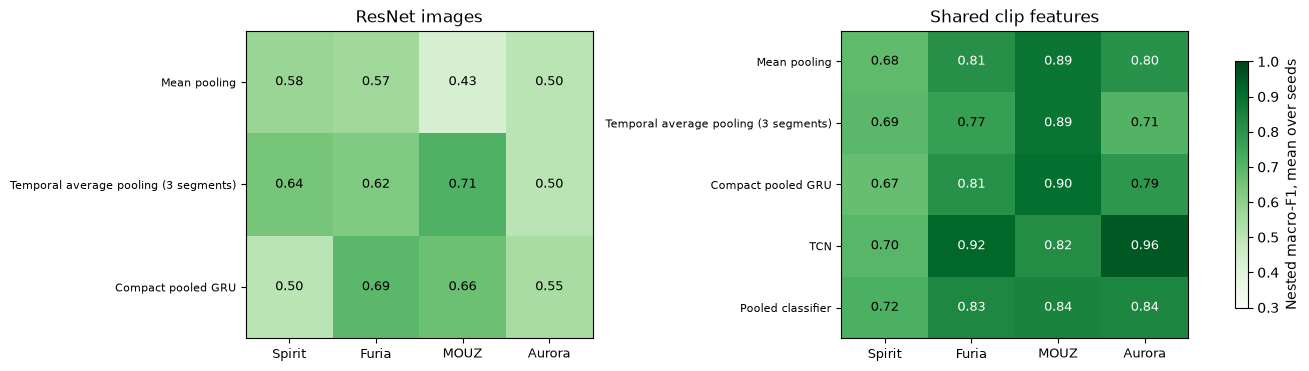

In [33]:
# @title Figure: nested macro-F1 per held-out match
panels = [(i, [m for m in MODELS if (m, i) in nested]) for i in ("ResNet images", "Shared clip features")]
panels = [(i, ms) for i, ms in panels if ms]
fig, axes = plt.subplots(1, len(panels), figsize=(13, 3.6), layout="constrained")
for ax, (inputs, ms) in zip(np.atleast_1d(axes), panels):
    values = np.array([[nested[(m, inputs)]["per_match"][mt] for mt in MATCHES] for m in ms])
    image = ax.imshow(values, cmap="Greens", vmin=0.3, vmax=1.0, aspect="auto")
    for r in range(len(ms)):
        for c in range(len(MATCHES)):
            ax.text(c, r, f"{values[r, c]:.2f}", ha="center", va="center", fontsize=9, color="white" if values[r, c] > 0.8 else "black")
    ax.set_xticks(range(len(MATCHES)), [MATCH_NAMES[mt].split(" vs ")[0] for mt in MATCHES], fontsize=9)
    ax.set_yticks(range(len(ms)), ms, fontsize=8)
    ax.set_title(inputs)
fig.colorbar(image, ax=axes, shrink=0.8, label="Nested macro-F1, mean over seeds")
plt.show()
E["q44"] = dict(hardest={i: min(MATCHES, key=lambda mt: np.mean([nested[(m, i)]["per_match"][mt] for m in ms])) for i, ms in panels})

**Answer.** The ranking of inputs holds on every match: for each model run on both inputs, shared clip features score higher on every held-out match. Scores still vary a lot between matches. On shared clip features Spirit vs Falcons is the hardest match on average, and on ResNet images Aurora vs Vitality is.

In [34]:
# @title Key numbers
q = E["q44"]
say("; ".join(f"hardest on {inp(i)}: {MATCH_NAMES[m]}" for i, m in q["hardest"].items()) + f"; largest spread between matches {max(spreads.values()):.3f}.")

hardest on ResNet images: Aurora vs Vitality; hardest on shared clip features: Spirit vs Falcons; largest spread between matches 0.257.

### 4.5 Which tactics are hardest?

Rows are the completed nested runs; columns are the five classes (with their clip counts) and a pooled macro-F1. Every clip is predicted by the model that held out its match, with class probabilities averaged over the seeds, and all clips are scored together. The pooled macro-F1 column is the mean of the five class F1 scores on these pooled predictions, so it can differ from the headline nested macro-F1, which is averaged per held-out match and seed.

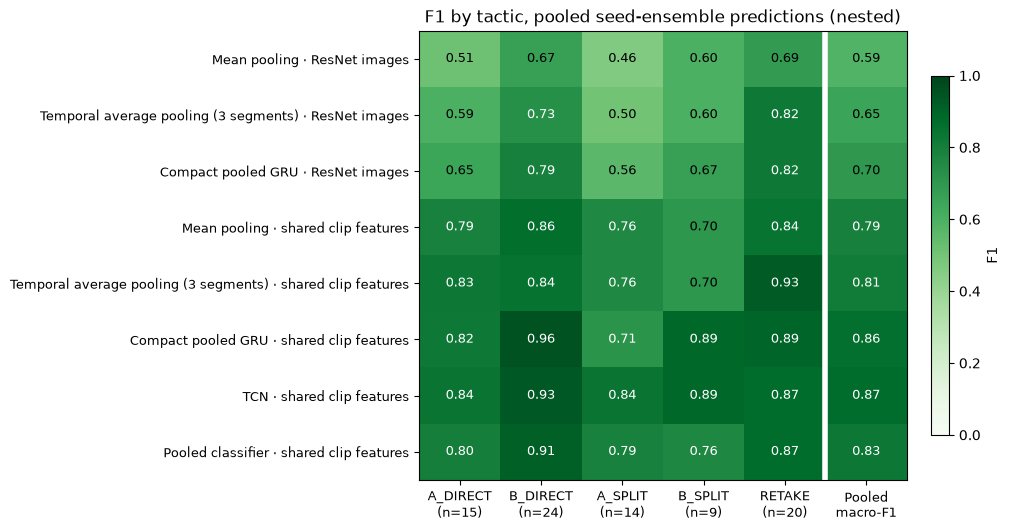

In [35]:
# @title Figure: F1 by tactic
rows45 = [(m, i) for i in INPUTS for m in MODELS if (m, i) in nested]
values = np.array([[nested[k]["pooled_f1"][c] for c in CLASSES] + [nested[k]["pooled_macro"]] for k in rows45])
fig, ax = plt.subplots(figsize=(10, 0.45 * len(rows45) + 1.6), layout="constrained")
image = ax.imshow(values, cmap="Greens", vmin=0, vmax=1, aspect="auto")
for r in range(values.shape[0]):
    for c in range(values.shape[1]):
        ax.text(c, r, f"{values[r, c]:.2f}", ha="center", va="center", fontsize=9, color="white" if values[r, c] > 0.7 else "black")
ax.axvline(len(CLASSES) - 0.5, color="white", linewidth=4)
ax.set_xticks(range(len(CLASSES) + 1), [f"{c}\n(n={totals[c]})" for c in CLASSES] + ["Pooled\nmacro-F1"], fontsize=9)
ax.set_yticks(range(len(rows45)), [f"{m} · {inp(i)}" for m, i in rows45], fontsize=9)
ax.set_title("F1 by tactic, pooled seed-ensemble predictions (nested)")
fig.colorbar(image, ax=ax, shrink=0.8, label="F1")
plt.show()
E["q45"] = dict(
    all={c: float(np.mean([nested[k]["pooled_f1"][c] for k in rows45])) for c in CLASSES},
    clip={c: float(np.mean([nested[k]["pooled_f1"][c] for k in rows45 if k[1] == "Shared clip features"])) for c in CLASSES},
    gaps={k: abs(nested[k]["pooled_macro"] - nested[k]["mean"]) for k in rows45},
)

**Answer.** A_SPLIT is the hardest class on average and also on shared clip features alone; RETAKE is the easiest on average. Splits are hard because they differ from direct attacks only by a second group of players.

In [36]:
# @title Key numbers
q = E["q45"]
say(f"Mean F1 over runs: A_SPLIT {q['all']['A_SPLIT']:.2f} (lowest), RETAKE {q['all']['RETAKE']:.2f} (highest).")

Mean F1 over runs: A_SPLIT 0.67 (lowest), RETAKE 0.84 (highest).

## 5. Where does the selected model go wrong?

### 5.1 Which classes does the selected model confuse?

The selected model is the strongest completed nested result. The confusion matrix counts its seed-ensemble predictions: each clip's class probabilities are averaged over the seeds of the model that held out its match. Rows are true classes, columns predicted classes; the diagonal is correct.

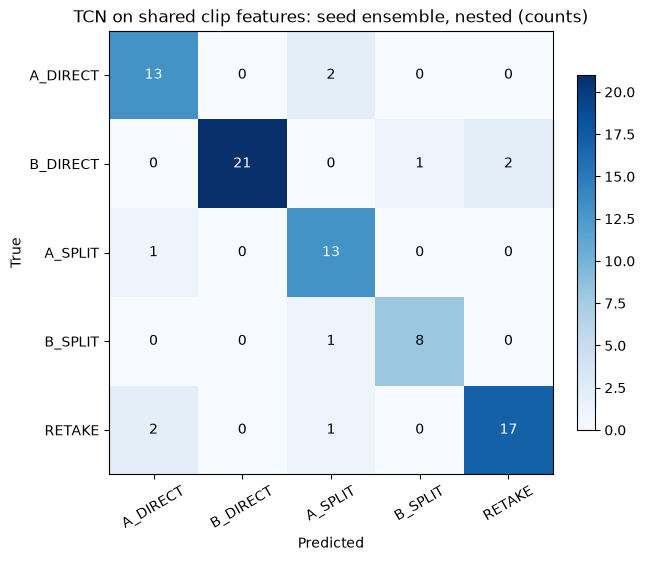

In [37]:
# @title Figure: confusion matrix of the selected model
model51, inputs51 = best_key
selected = nested[best_key]
matrix = selected["confusion"]
fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
image = ax.imshow(matrix, cmap="Blues")
for i in range(5):
    for j in range(5):
        ax.text(j, i, matrix[i, j], ha="center", va="center", color="white" if matrix[i, j] > matrix.max() / 2 else "black")
ax.set_xticks(range(5), CLASSES, rotation=30)
ax.set_yticks(range(5), CLASSES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"{model51} on {inp(inputs51)}: seed ensemble, nested (counts)")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()


def error_kind(r):
    t, p = CLASSES[r["truth"]], CLASSES[int(r["probs"].argmax())]
    if (t == "RETAKE") != (p == "RETAKE"):
        return "attack/retake"
    return "split/direct" if SITE[t] == SITE[p] else "wrong site"


selected_errors = sorted((r for r in selected["clip_rows"] if int(r["probs"].argmax()) != r["truth"]), key=lambda r: -r["probs"].max())
E["q51"] = dict(
    total=int(matrix.sum()), accuracy=float(np.trace(matrix) / matrix.sum()),
    group=int(sum(matrix[i, j] for i, t in enumerate(CLASSES) for j, p in enumerate(CLASSES) if SITE[t] == SITE[p])),
    given=int(sum(matrix[i, j] for i, t in enumerate(CLASSES) for j, p in enumerate(CLASSES) if SITE[t] == SITE[p] and SITE[t] != "RETAKE")),
    exact=int(sum(matrix[i, i] for i, t in enumerate(CLASSES) if SITE[t] != "RETAKE")),
    kinds={k: sum(error_kind(r) == k for r in selected_errors) for k in ("attack/retake", "split/direct", "wrong site")},
)

**Answer.** Nearly every clip gets the right group (A, B or retake), and nearly every attack whose site is right is also labelled split or direct correctly. Among the mistakes, confusing an attack with a retake is the most common, then confusing split and direct at the same site; wrong-site errors are the rarest.

In [38]:
# @title Key numbers
q = E["q51"]
say(f"Right group {q['group']} of {q['total']}; split vs direct right {q['exact']} of {q['given']}; errors: " + ", ".join(f"{k} {n}" for k, n in q["kinds"].items()) + ".")

Right group 76 of 82; split vs direct right 55 of 59; errors: attack/retake 5, split/direct 4, wrong site 1.

### 5.2 Which errors is the selected model most sure about?

The table lists the selected model's most confident errors: the wrong answers to which it gave the highest seed-ensemble probability. Clips are named by match and clip number. Possible causes are hypotheses, because the footage of these clips was not reviewed for this report.

In [39]:
# @title Table: the most confident errors
TOP = 5
show_table("confident-errors", 
    pd.DataFrame(
        [[r["clip_id"].split(".")[-1], MATCH_NAMES[match_of(r["clip_id"])], CLASSES[r["truth"]], CLASSES[int(r["probs"].argmax())], float(r["probs"].max())] for r in selected_errors[:TOP]],
        columns=["Clip", "Match", "True", "Predicted", "Probability of prediction"],
    )
)
E["q52"] = dict(per_match={mt: sum(match_of(r["clip_id"]) == mt for r in selected_errors) for mt in MATCHES}, top_kinds={error_kind(r) for r in selected_errors[:TOP]})

Clip,Match,True,Predicted,Probability of prediction
s006,Spirit vs Falcons,B_DIRECT,RETAKE,0.876
s014,MOUZ vs BetBoom,RETAKE,A_DIRECT,0.795
s011,Spirit vs Falcons,B_DIRECT,B_SPLIT,0.713
s012,MOUZ vs BetBoom,A_DIRECT,A_SPLIT,0.698
s011,Furia vs Falcons,RETAKE,A_SPLIT,0.644


**Answer.** The most confident errors mix both kinds of confusion from 5.1, and Spirit vs Falcons has the most errors of any match. **Hypotheses** (footage not reviewed): split/direct mix-ups may come from a second group that is small, late or not detected on the minimap; attack/retake mix-ups may come from clip boundaries, for example a retake clip that still contains the attack before the plant; a wrong-site error may come from a fake or a late rotation within the clip.

In [40]:
# @title Key numbers
q = E["q52"]
worst = max(q["per_match"], key=q["per_match"].get)
say(f"{MATCH_NAMES[worst]}: {q['per_match'][worst]} of {len(reference[worst])} clips wrong (most of any match).")

Spirit vs Falcons: 5 of 21 clips wrong (most of any match).

## 6. What limits these results, and which model do we choose?

### 6.1 What limits these results?

The limits below concern the evaluation and the inputs. The table shows how much other-folds epoch selection changes the image models' scores.

In [41]:
# @title Table: other-folds minus nested for the image models
gaps61 = []
for m in MODELS:
    a, b = results.get((m, "ResNet images", "nested")), results.get((m, "ResNet images", "other-folds"))
    if a and b:
        gaps61.append((m, b["mean"] - a["mean"]))
for version, d in gru_versions.items():
    if version != "compact_pooled" and d["nested"] and d["other-folds"]:
        gaps61.append((GRU_NAMES[version], d["other-folds"]["mean"] - d["nested"]["mean"]))
show_table("other-folds-minus-nested", pd.DataFrame(gaps61, columns=["Model (ResNet images)", "Other-folds − nested macro-F1"]))
E["q61"] = dict(gaps=gaps61)

Model (ResNet images),Other-folds − nested macro-F1
Mean pooling,0.066
Temporal average pooling (3 segments),0.030
Compact pooled GRU,0.081
Last-state GRU,-0.006
Compact last-state GRU,0.027


**Answer.** - **Other-folds epoch selection is optimistic for most image models** (table above; Appendix A1), so nested scores are the main estimate.
- **Map regions were adjusted after looking at training labels** ([shared clip features](../docs/clip-data.md#map-regions)), so every score on shared clip features may be optimistic.
- **Inputs are detections, not game truth**, and the detector's empty-map background is built from the same match's frames (pixels only, no labels), including the held-out match.
- **Clip boundaries were cut by hand**, so where a clip starts and ends could hint at its class; this was not tested.
- **Review was independent for only two of the matches** (1.2).
- **Only four development matches, with a large spread between them** (4.4).
- **Test history.** This notebook uses development matches only. Earlier TCN experiments evaluated the test matches separately.

In [42]:
# @title Key numbers
q = E["q61"]
say(f"Other-folds higher for {sum(g > 0 for _, g in q['gaps'])} of {len(q['gaps'])} image models; largest spread between held-out matches {max(spreads.values()):.3f}.")

Other-folds higher for 4 of 5 image models; largest spread between held-out matches 0.257.

### 6.2 Which model do we choose?

The choice is made among completed nested runs only, and is weighed against the same-input control (4.3) and the spread between held-out matches (4.4).

In [43]:
# @title Table: the selected model and its same-input control
control_key = ("Pooled classifier", best_key[1])
show_table("selected-vs-control", 
    pd.DataFrame(
        [[f"{m} · {inp(i)}", fmt(nested[(m, i)]), spreads[(m, i)]] for m, i in (best_key, control_key) if (m, i) in nested],
        columns=["Run", "Nested macro-F1", "Spread between held-out matches"],
    )
)
E["q62"] = dict(margin=nested[best_key]["mean"] - nested[control_key]["mean"] if control_key in nested else None,
                leads=sum(nested[best_key]["per_match"][m] > nested[control_key]["per_match"][m] for m in MATCHES) if control_key in nested else None)

Run,Nested macro-F1,Spread between held-out matches
TCN · shared clip features,0.849 ± 0.021,0.257
Pooled classifier · shared clip features,0.809 ± 0.035,0.124


**Answer.** Among completed nested runs we prefer the **TCN on shared clip features**: it has the highest nested macro-F1. Its margin over the same-input pooled control is small, much smaller than the spread between its own held-out matches, and it led on only half of them. With only four development matches, map regions drawn with knowledge of the training labels and partial label review, the choice is an estimate rather than a settled ranking.

In [44]:
# @title Key numbers
q = E["q62"]
say(f"Margin over the pooled control {q['margin']:+.3f}; spread between the TCN's held-out matches {spreads[best_key]:.3f}; led on {q['leads']} of {len(MATCHES)} matches." if q["margin"] is not None else DASH)

Margin over the pooled control +0.040; spread between the TCN's held-out matches 0.257; led on 2 of 4 matches.

## Appendix

### A1. How optimistic is other-folds epoch selection?

Other-folds epoch selection scores each held-out match at the epoch that was best on the other held-out matches, whose models were trained on the scored match. Nested selection never uses the scored match.

In [45]:
# @title Table: nested vs other-folds epoch selection
rows_a1 = []
for i in INPUTS:
    for m in MODELS:
        a, b = results.get((m, i, "nested")), results.get((m, i, "other-folds"))
        if a or b:
            rows_a1.append([m, i, fmt(a), fmt(b), b["mean"] - a["mean"] if a and b else DASH])
for version in ("laststate", "compact_laststate"):
    a, b = gru_versions[version]["nested"], gru_versions[version]["other-folds"]
    if a or b:
        rows_a1.append([GRU_NAMES[version], "ResNet images", fmt(a), fmt(b), b["mean"] - a["mean"] if a and b else DASH])
show_table("epoch-selection", pd.DataFrame(rows_a1, columns=["Model", "Input", "Nested", "Other-folds", "Other-folds − nested"]))
diffs_a1 = [r[4] for r in rows_a1 if not isinstance(r[4], str)]
other_sources = sorted({r["per_seed_source"] for (m, i, rule), r in results.items() if rule == "other-folds"})
say(f"Other-folds minus nested ranges from {min(diffs_a1):+.3f} to {max(diffs_a1):+.3f} across the {len(diffs_a1)} pairs with both; {sum(d > 0 for d in diffs_a1)} are positive. Per-seed other-folds scores: " + "; ".join(other_sources) + ".")

Model,Input,Nested,Other-folds,Other-folds − nested
Mean pooling,ResNet images,0.518 ± 0.034,0.584 ± 0.016,0.066
Temporal average pooling (3 segments),ResNet images,0.620 ± 0.015,0.650 ± 0.013,0.030
Compact pooled GRU,ResNet images,0.600 ± 0.028,0.681 ± 0.049,0.081
TCN,Detector features,—,0.679 ± 0.016,—
Pooled classifier,Detector features,—,0.645 ± 0.018,—
Mean pooling,Shared clip features,0.796 ± 0.016,0.790 ± 0.022,-0.007
Temporal average pooling (3 segments),Shared clip features,0.763 ± 0.048,0.775 ± 0.018,0.012
Compact pooled GRU,Shared clip features,0.792 ± 0.033,0.809 ± 0.034,0.017
TCN,Shared clip features,0.849 ± 0.021,0.834 ± 0.026,-0.015
Pooled classifier,Shared clip features,0.809 ± 0.035,0.823 ± 0.027,0.014


Other-folds minus nested ranges from -0.015 to +0.081 across the 10 pairs with both; 7 are positive. Per-seed other-folds scores: recomputed from predictions.csv; saved cross-validation history (per-seed predictions not saved).

### A2. Do the procedures learn anything from shuffled labels?

Each check refits the whole procedure with labels shuffled within each match and scores against the shuffled labels. A sound procedure lands near chance.

In [46]:
# @title Table: shuffled-label checks
checks_a2 = []
for key, model, name, inputs in (
    ("img_nested", "mean", "Mean pooling", "ResNet images"),
    ("img_nested", "thirds", "Temporal average pooling (3 segments)", "ResNet images"),
    ("img_other", "mean", "Mean pooling", "ResNet images"),
    ("img_other", "thirds", "Temporal average pooling (3 segments)", "ResNet images"),
    ("img_other", "gru", GRU_NAMES["laststate"], "ResNet images"),
    ("random_segments", "random-thirds", "Random-segment control", "ResNet images"),
    ("gru_shuffled", "gru", GRU_NAMES["compact_pooled"], "ResNet images"),
):
    folder = runs.get(key)
    path = folder / model / "shuffled-labels.json" if folder else None
    if path and path.is_file():
        check = json.loads(path.read_text(encoding="utf-8"))
        shuffled = [p["macro_f1"] for p in check["permutations"]]
        rule = json.loads((folder / model / "config.json").read_text(encoding="utf-8"))["epoch_mode"]
        checks_a2.append([name, inputs, rule, check["real"]["macro_f1"], float(np.mean(shuffled)), max(shuffled), f"{check['at_least_real']} of {check['count']}"])
folder = runs.get("tcn_clip_shuffled")
real = results.get(("TCN", "Shared clip features", "other-folds"))
if folder and real:
    shuffled = [json.loads(p.read_text(encoding="utf-8"))["models"]["tcn"]["cross_fold_macro_f1"] for p in sorted(folder.glob("permutation-*.json"))]
    checks_a2.append(["TCN", "Shared clip features", "other-folds", real["mean"], float(np.mean(shuffled)), max(shuffled), f"{sum(v >= real['mean'] for v in shuffled)} of {len(shuffled)}"])
show_table("shuffled-labels", pd.DataFrame(checks_a2, columns=["Model", "Input", "Epoch selection", "Real macro-F1", "Shuffled: mean", "Shuffled: highest", "Shuffled at or above real"]))
checked_a2 = {(c[0], c[1]) for c in checks_a2}
without = list(dict.fromkeys(f"{m} on {inp(i)}" for (m, i, _) in results if (m, i) not in checked_a2))
say(f"No shuffled refit reached its real score in {sum(c[6].startswith('0 of') for c in checks_a2)} of {len(checks_a2)} checks. Without a shuffled-label check: " + "; ".join(without) + ".")

Model,Input,Epoch selection,Real macro-F1,Shuffled: mean,Shuffled: highest,Shuffled at or above real
Mean pooling,ResNet images,nested,0.518,0.146,0.281,0 of 20
Temporal average pooling (3 segments),ResNet images,nested,0.620,0.155,0.271,0 of 20
Mean pooling,ResNet images,other-folds,0.584,0.179,0.314,0 of 20
Temporal average pooling (3 segments),ResNet images,other-folds,0.650,0.168,0.295,0 of 20
Last-state GRU,ResNet images,other-folds,0.338,0.180,0.278,0 of 20
Random-segment control,ResNet images,nested,0.526,0.142,0.276,0 of 20
Compact pooled GRU,ResNet images,other-folds,0.681,0.176,0.264,0 of 20
TCN,Shared clip features,other-folds,0.834,0.175,0.230,0 of 20


No shuffled refit reached its real score in 8 of 8 checks. Without a shuffled-label check: Mean pooling on shared clip features; Temporal average pooling (3 segments) on shared clip features; Compact pooled GRU on shared clip features; Pooled classifier on shared clip features; TCN on detector features; Pooled classifier on detector features.

### A3. What settings did each model use?

In [47]:
# @title Table: full training settings, from the saved configurations
def temporal_row(family, inputs, r):
    s, t = r["config"]["settings"], r["config"].get("temporal", {})
    return [family, inputs, "AdamW", s["learning_rate"], s["weight_decay"], "full batch", f"up to {s['epochs']}, stop after {s['patience']} without gain",
            t.get("dropout", 0.0) if "projection" in t else 0.0, 0.0, "none", "on" if s.get("class_weights", True) else "off"]


def tcn_row(family, inputs, r):
    c = r["config"]
    augmentation = f"position jitter {c['jitter']}, {c['drop']:.0%} detections dropped" if c["input"] == "detections" else "none"
    return [family, inputs, f"AdamW, warm-up {c['warmup_epochs']} epochs", c["lr"], c["weight_decay"], c["batch"], f"up to {c['epochs']}, checked every {c['eval_every']}",
            c["dropout"], c["label_smoothing"], augmentation, "on"]


rows_a3 = []
for family, key in (("Mean pooling and temporal average pooling", ("Mean pooling", "Shared clip features", "nested")), ("Compact pooled GRU", ("Compact pooled GRU", "Shared clip features", "nested"))):
    if key in results:
        rows_a3.append(temporal_row(family, "ResNet images, shared clip features", results[key]))
for key in (("TCN", "Detector features", "other-folds"), ("TCN", "Shared clip features", "nested")):
    if key in results:
        rows_a3.append(tcn_row("TCN and pooled classifier", key[1], results[key]))
show_table("training-settings", pd.DataFrame(rows_a3, columns=["Model family", "Input", "Optimiser", "Learning rate", "Weight decay", "Batch size", "Epochs", "Dropout", "Label smoothing", "Augmentation", "Class weighting"]))
KEYS = ("learning_rate", "weight_decay", "epochs", "patience", "class_weights")
same = all(
    results[(m, "ResNet images", "nested")]["config"]["settings"].get(k, True) == results[(m, "Shared clip features", "nested")]["config"]["settings"].get(k, True)
    for m in ("Mean pooling", "Temporal average pooling (3 segments)", "Compact pooled GRU")
    if (m, "ResNet images", "nested") in results and (m, "Shared clip features", "nested") in results
    for k in KEYS
)
say("Values are read from each run's saved configuration. " + ("The image runs of mean pooling, temporal average pooling and the Compact pooled GRU use the same settings as their shared-clip-feature runs." if same else "Image and shared-clip-feature runs differ in some settings; see their config.json files."))

Model family,Input,Optimiser,Learning rate,Weight decay,Batch size,Epochs,Dropout,Label smoothing,Augmentation,Class weighting
Mean pooling and temporal average pooling,"ResNet images, shared clip features",AdamW,0.010,0.001,full batch,"up to 200, stop after 30 without gain",0.000,0.000,none,on
Compact pooled GRU,"ResNet images, shared clip features",AdamW,0.010,0.001,full batch,"up to 200, stop after 30 without gain",0.300,0.000,none,on
TCN and pooled classifier,Detector features,"AdamW, warm-up 5 epochs",0.001,0.010,8,"up to 150, checked every 10",0.200,0.050,"position jitter 0.005, 5% detections dropped",on
TCN and pooled classifier,Shared clip features,"AdamW, warm-up 5 epochs",0.001,0.010,8,"up to 150, checked every 10",0.200,0.050,none,on


Values are read from each run's saved configuration. The image runs of mean pooling, temporal average pooling and the Compact pooled GRU use the same settings as their shared-clip-feature runs.

### A4. What were the three GRU designs in full?

In [48]:
# @title Table: the three GRU designs
rows_a4 = []
for version, d in gru_versions.items():
    r = d["nested"] or d["other-folds"]
    if r is None:
        rows_a4.append([GRU_NAMES[version]] + [DASH] * 7)
        continue
    t = r["config"]["temporal"]
    rows_a4.append([GRU_NAMES[version], t["projection"], t["hidden"], t.get("dropout", 0.0),
                    "mean and max over real frames" if t.get("readout", "last") == "mean-max" else "last state",
                    int(r["config"]["trainable_parameters"]), fmt(d["nested"]), fmt(d["other-folds"])])
show_table("gru-design-settings", pd.DataFrame(rows_a4, columns=["GRU design (ResNet images)", "Frame projection", "Memory size", "Dropout", "Readout", "Trainable weights", "Nested macro-F1", "Other-folds macro-F1"]))
say("Each design was fixed before its score was seen; the Compact pooled GRU was selected and is the GRU compared in section 4.")

GRU design (ResNet images),Frame projection,Memory size,Dropout,Readout,Trainable weights,Nested macro-F1,Other-folds macro-F1
Last-state GRU,32,32,0.000,last state,23109,0.345 ± 0.008,0.338 ± 0.011
Compact last-state GRU,8,16,0.300,last state,5533,0.327 ± 0.004,0.354 ± 0.020
Compact pooled GRU,8,16,0.300,mean and max over real frames,5613,0.600 ± 0.028,0.681 ± 0.049


Each design was fixed before its score was seen; the Compact pooled GRU was selected and is the GRU compared in section 4.

### A5. How can these results be reproduced?

**Kernel.** Use the project's `.venv` (setup in the [README](../README.md)) as the notebook kernel and run every cell from top to bottom. The notebook trains nothing and writes nothing, and it never reads the test matches. Besides the project itself it needs numpy, pandas, matplotlib, IPython (Jupyter), opencv-python (2.2) and torch (2.2 and 4.3 import the project's detector and TCN code); the check below prints their versions.

**Run folders and data.** The result files the notebook reads (the `.json`, `.csv` and `.md` files of the run folders in the setup cell) are tracked in Git, so a clone can rerun it; checkpoints and feature caches are not needed. The label records of the development matches and, for 2.2, the detector's saved detections of one training clip are in Git too. Figures 2.2 and 2.3 and some checks also need the train-only dataset and clip-data copies (`data/processed/datasets/2026-11-16-train-only` and `data/processed/clip-data-2026-11-16-train-only`); without them they show "—" or "unverified". How to make the clip-data copy: [Clip-data inputs](../docs/tactic-temporal.md#clip-data-inputs) in docs/tactic-temporal.md; the dataset copy is the export with an empty test manifest (see "Repeat the experiments" below). The check below prints what was found and what the setup cells verified.

In [49]:
# @title Run folders found, checks and environment
import platform
from importlib.metadata import PackageNotFoundError, version


def installed(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return "not installed"


for name, folder in {**runs, **data}.items():
    path = RUNS.get(name, DATA.get(name))
    print(f"{'found  ' if folder else 'MISSING'}  {name:<33} {folder.relative_to(ROOT).as_posix() if folder else path}")
passed = sum(p is True for *_, p in AUDIT)
skipped = sorted({check for _, check, p in AUDIT if p is None})
print(
    f"\nPrediction files: {passed} checks passed (unique and complete (clip_id, seed) keys, labels matching the training manifest, "
    "fold membership from the CSVs matching the fold records, epoch metadata)."
    + (f" Not checked (evidence missing): {'; '.join(skipped)}." if skipped else "")
)
fold_checks = [a for a in AGREE if a[4] == "fold record"]
report_checks = [a for a in AGREE if a[4] == "summary report"]
print(f"Scores recomputed from the prediction files agree with the fold records: {len(fold_checks)} values within {TOLERANCE:g}.")
print(f"Agreement between saved reports: the runs' summary reports agree with the recomputed scores: {len(report_checks)} values within {TOLERANCE:g}.")
print("Per-seed scores: " + "; ".join(sorted({f"{r['per_seed_source']}" for _, r in everything})) + ".")
print(f"Loaded {len(everything)} results. All use the same {N_CLIPS} clips (the included clips of the training manifest), the same {len(reference)} held-out matches, seeds 0-{N_SEEDS - 1} and the epoch selection they are labelled with.")
executable = Path(sys.executable)
try:
    executable = executable.relative_to(ROOT).as_posix()
except ValueError:
    executable = executable.name
saved = results[("Mean pooling", "ResNet images", "nested")]["config"]
print(f"\nNotebook kernel: Python {platform.python_version()} ({executable}); " + ", ".join(f"{p} {installed(p)}" for p in ("numpy", "pandas", "matplotlib", "ipython", "opencv-python", "torch")) + ".")
print(f"Training runs (from config.json): Python {saved.get('python', '?')}; " + ", ".join(f"{k} {v}" for k, v in saved.get("versions", {}).items()) + f"; device {saved.get('device', '?')}.")

found    img_nested                        runs/tactic-temporal-20261116
found    img_gru_pooled_nested             runs/tactic-gru-nested-20261120
found    img_gru_laststate_nested          runs/tactic-gru-first-nested-20261120
found    img_gru_compact_laststate_nested  runs/tactic-gru-middle-nested-20261120
found    img_thirds_unweighted             runs/tactic-thirds-unweighted-nested-20261120
found    img_other                         runs/tactic-temporal-other-folds-20261119
found    img_gru_compact_laststate_other   runs/tactic-gru-small-other-folds-20261119
found    img_gru_pooled_other              runs/tactic-gru-pooled-other-folds-20261119
found    clip_nested                       runs/tactic-clipdata-nested-20261120
found    clip_other                        runs/tactic-clipdata-other-folds-20261120
found    tcn_clip_nested                   runs/tactic-tcn-clipdata-nested-20261120
found    tcn_clip_other                    runs/tactic-tcn-clipdata-repro-20261119
found    t

**Repeat the experiments.** Data: the 2026-11-16 export with the uncertain clip left out (`--exclude-uncertain`), and shared clip features built with regions `mirage-spectator-v1`. Use the train-only copies so the test matches are never read: `data/processed/datasets/2026-11-16-train-only` (empty test manifest) and `data/processed/clip-data-2026-11-16-train-only` (train `.npz` files, `channels.json`, and an `index.csv` with only train rows). Pick a new `$TAG`; every output folder must be new, and later steps use the fresh outputs of earlier ones. Run from the repository root (PowerShell):

```powershell
$TAG = "<new tag>"                                        # e.g. a date; output folders must not exist
$M = "data/processed/datasets/2026-11-16-train-only/train/manifest.csv"
$D = "data/processed/datasets/2026-11-16-train-only"
$C = "data/processed/clip-data-2026-11-16-train-only"
# Train-only dataset copy, made once: the export's train/ folder, and a test manifest with only the
# header row (taken from the train manifest, so the test manifest is never read)
$EXPORT = "data/processed/datasets/2026-11-16"
if (-not (Test-Path $D)) {
    New-Item -ItemType Directory "$D/test" | Out-Null
    Copy-Item -Recurse "$EXPORT/train" "$D/train"
    Get-Content "$EXPORT/train/manifest.csv" -TotalCount 1 | Set-Content "$D/test/manifest.csv" -Encoding ascii
}
$GRU_LAST = "--gru-projection 32 --gru-hidden 32 --gru-dropout 0 --gru-readout last".Split(" ")   # Last-state GRU
$GRU_COMPACT_LAST = "--gru-readout last".Split(" ")       # Compact last-state GRU (8/16, dropout 0.3 are the defaults)
# ResNet images, nested: mean pooling and temporal average pooling, 20 shuffled-label refits; computes the frame features
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-temporal-$TAG --exclude-uncertain --models mean thirds --shuffles 20
$F = "runs/tactic-temporal-$TAG/frame-features.pt"
# The three GRU designs on ResNet images, nested
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-nested-$TAG --exclude-uncertain --models gru --features $F                 # Compact pooled GRU
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-laststate-nested-$TAG --exclude-uncertain --models gru --features $F @GRU_LAST
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-compact-laststate-nested-$TAG --exclude-uncertain --models gru --features $F @GRU_COMPACT_LAST
# Class weights off; random-segment control
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-thirds-unweighted-nested-$TAG --exclude-uncertain --models thirds --features $F --no-class-weights
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-temporal-random-thirds-$TAG --exclude-uncertain --models random-thirds --features $F --shuffles 20
# ResNet images, other-folds epoch selection: mean, temporal average and the Last-state GRU (as in the historical run), then the compact GRUs
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-temporal-other-folds-$TAG --exclude-uncertain --models mean thirds gru --features $F --epoch-mode other-folds --shuffles 20 @GRU_LAST
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-compact-laststate-other-folds-$TAG --exclude-uncertain --models gru --features $F --epoch-mode other-folds @GRU_COMPACT_LAST
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-pooled-other-folds-$TAG --exclude-uncertain --models gru --features $F --epoch-mode other-folds
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-shuffled-other-folds-$TAG --exclude-uncertain --models gru --features $F --epoch-mode other-folds --shuffles 20
# Shared clip features: mean pooling, temporal average pooling and the Compact pooled GRU, nested then other-folds (stops at the first failure)
bash scripts/clipdata_temporal_20261120.sh $TAG
# Shared clip features: TCN and pooled classifier, nested; then per-epoch TCN curves from that fresh run (3.3)
python scripts/nested_tcn.py --dataset $D --clip-data $C --output runs/tactic-tcn-clipdata-nested-$TAG --models tcn control
python scripts/tcn_curves.py --dataset $D --clip-data $C --nested runs/tactic-tcn-clipdata-nested-$TAG --output runs/tactic-tcn-clipdata-curves-$TAG --held-out spirit-falcons-mirage-cologne-major --seed 0 --model tcn
# TCN and pooled classifier, other-folds (train-tactics cross-validation): shared clip features, then detector features
python -m stratscout train-tactics --dataset $D --clip-data $C --output runs/tactic-tcn-clipdata-$TAG --exclude-uncertain --seeds 3
python -m stratscout train-tactics --dataset $D --output runs/tactic-tcn-$TAG --exclude-uncertain --seeds 3
# Shuffled labels for the TCN on shared clip features
python scripts/shuffle_tcn.py --dataset $D --clip-data $C --output runs/tactic-tcn-clipdata-shuffled-$TAG --models tcn --start 0 --count 20
```

To read fresh runs, point the entries of `RUNS` in the first code cell at the new folders.

### A6. Exact numbers and checks for each answer

For each question, the exact numbers behind the answer, followed by checks of every claim the answer makes. A failed check stops the notebook; a claim whose evidence is missing, or which cannot be checked from the saved files, is listed as unverified rather than checked.

#### 1.2 What data do the models learn from?

In [50]:
# @title 1.2: exact numbers and checks
spirit = "spirit-falcons-mirage-cologne-major"
share = by_match[spirit]["B_DIRECT"] / sum(by_match[spirit].values())
excluded = image_config.get("excluded_clip_ids", [])
review = E["q12"]["review"]
bullets(
    [f"{c}: {totals[c]} clips" for c in CLASSES]
    + ["Clips per match: " + ", ".join(f"{MATCH_NAMES[m]} {sum(by_match[m].values())}" for m in MATCHES)]
    + [f"B_DIRECT share in Spirit vs Falcons: {share:.0%}"]
    + [f"Left out as uncertain: {len(excluded)} clip" + ("s" if len(excluded) != 1 else "") + (" (" + ", ".join(f"{MATCH_NAMES[match_of(c)]} {c.split('.')[-1]}" for c in excluded) + ")" if excluded else "")]
    + ([f"{MATCH_NAMES[m]}: {v['clips']} included clips, {v['reviewed']} marked reviewed, {v['second']} reviewed by a second team member" for m, v in review.items()] if review else [])
)
claims(
    [
        ("B_DIRECT is the largest class", lambda: large == "B_DIRECT", totals),
        ("B_SPLIT is the smallest class", lambda: small == "B_SPLIT", totals),
        ("every match has clips of every class", lambda: all(by_match[m][c] > 0 for m in MATCHES for c in CLASSES), by_match),
        ("B_DIRECT is about half of Spirit vs Falcons", lambda: 0.4 <= share <= 0.6, by_match),
        ("all included clips were marked reviewed before export", lambda: all(v["reviewed"] == v["clips"] for v in review.values()), review),
        ("a second team member reviewed the segments of Furia and Spirit", lambda: all(review[m]["second"] >= review[m]["clips"] - 1 for m in ("furia-falcons-mirage-cologne-major-2026", "spirit-falcons-mirage-cologne-major")), review),
        ("no segment of Aurora or MOUZ was reviewed by a second team member", lambda: all(review[m]["second"] == 0 for m in ("aurora-vitality-mirage-esl-pro-league-season-24", "mouz-betboom-mirage-iem-bejing-2026")), review),
        ("for Aurora and MOUZ a second team member answered the flagged rounds (from labels/review-notes.md, not in the label records)", None),
    ]
)

- A_DIRECT: 15 clips
- B_DIRECT: 24 clips
- A_SPLIT: 14 clips
- B_SPLIT: 9 clips
- RETAKE: 20 clips
- Clips per match: Spirit vs Falcons 21, Furia vs Falcons 22, MOUZ vs BetBoom 20, Aurora vs Vitality 19
- B_DIRECT share in Spirit vs Falcons: 52%
- Left out as uncertain: 1 clip (Spirit vs Falcons s005)
- Spirit vs Falcons: 21 included clips, 21 marked reviewed, 20 reviewed by a second team member
- Furia vs Falcons: 22 included clips, 22 marked reviewed, 22 reviewed by a second team member
- MOUZ vs BetBoom: 20 included clips, 20 marked reviewed, 0 reviewed by a second team member
- Aurora vs Vitality: 19 included clips, 19 marked reviewed, 0 reviewed by a second team member

**Checked:** B_DIRECT is the largest class; B_SPLIT is the smallest class; every match has clips of every class; B_DIRECT is about half of Spirit vs Falcons; all included clips were marked reviewed before export; a second team member reviewed the segments of Furia and Spirit; no segment of Aurora or MOUZ was reviewed by a second team member.

**Unverified (evidence missing or not checkable here):** for Aurora and MOUZ a second team member answered the flagged rounds (from labels/review-notes.md, not in the label records).

#### 1.3 Why macro-F1?

In [51]:
# @title 1.3: exact numbers and checks
q = E["q13"]
bullets([f"Largest class {large}: {totals[large]} of {N_CLIPS} clips; smallest {small}: {totals[small]}", f"Always {large}: accuracy {q['accuracy']:.3f}, macro-F1 {q['macro']:.3f}"])
claims(
    [
        ("the lazy model's macro-F1 is far below its accuracy", lambda: q["macro"] < q["accuracy"] / 2, q),
        ("the lazy model's macro-F1 is close to zero", lambda: q["macro"] < 0.15, q),
    ]
)

- Largest class B_DIRECT: 24 of 82 clips; smallest B_SPLIT: 9
- Always B_DIRECT: accuracy 0.293, macro-F1 0.091

**Checked:** the lazy model's macro-F1 is far below its accuracy; the lazy model's macro-F1 is close to zero.

#### 2.1 How does a clip become a prediction?

In [52]:
# @title 2.1: exact numbers and checks
bullets(
    [
        f"Image models: {n_frames} evenly sampled frames per clip, {resnet_width} ResNet numbers per frame",
        f"Shared clip features: {rate:.0f} rows per second (median {np.median(list(rows_per_clip.values())):.0f} rows per clip); "
        f"{detector_channels} detector channels in total (regions, bomb, timing) + {pcs} ResNet components",
    ]
)
claims(
    [
        ("each shared-clip-feature row is the detector channels plus the ResNet components", lambda: clip_summary["row_width"] == detector_channels + pcs, clip_summary),
        ("the ResNet part is compressed to a few components", lambda: pcs < resnet_width, clip_summary),
    ]
)

- Image models: 16 evenly sampled frames per clip, 512 ResNet numbers per frame
- Shared clip features: 5 rows per second (median 98 rows per clip); 72 detector channels in total (regions, bomb, timing) + 32 ResNet components

**Checked:** each shared-clip-feature row is the detector channels plus the ResNet components; the ResNet part is compressed to a few components.

#### 2.2 What does the detector see?

In [53]:
# @title 2.2: exact numbers and checks
q = E["q22"]
if q:
    bullets([f"Frame {q['frame'] + 1}: {q['t']} T and {q['ct']} CT detections; bomb detected: {'yes' if q['bomb'] else 'no'}",
             f"Detections inside a named region: {q['in_region']} of {q['detections']}", "Regions with a T detection: " + ", ".join(q["t_regions"])])
claims(
    [
        ("the frame has T, CT and bomb detections", lambda: q["t"] > 0 and q["ct"] > 0 and q["bomb"], q),
        ("all detections in this frame fall inside a named region", lambda: q["in_region"] == q["detections"], q),
        ("Ts were detected in several regions, including connector", lambda: len(q["t_regions"]) > 1 and "connector" in q["t_regions"], q),
    ]
)

- Frame 2: 5 T and 5 CT detections; bomb detected: yes
- Detections inside a named region: 10 of 10
- Regions with a T detection: a_ramp, connector, mid, palace

**Checked:** the frame has T, CT and bomb detections; all detections in this frame fall inside a named region; Ts were detected in several regions, including connector.

#### 2.3 What do shared clip features look like?

In [54]:
# @title 2.3: exact numbers and checks
q = E["q23"]
if q:
    for label in q["share"]:
        bullets([f"{label}: share of rows with a T detection in " + ", ".join(f"{r.replace('_', ' ')} {q['share'][label][r]:.0%}" for r in ("connector", "palace", "a_ramp", "mid", "a_site"))
                 + "; bomb " + ", ".join(f"{b.replace('bomb_', '')} {q['bomb'][label][b]:.0%}" for b in q["bomb"][label])])
claims(
    [
        ("a T was detected in connector on every sampled row of the A_SPLIT clip", lambda: q["share"]["A_SPLIT"]["connector"] == 1.0, q),
        ("Ts were detected in palace and ramp in both clips", lambda: all(q["share"][l]["palace"] > 0 and q["share"][l]["a_ramp"] > 0 for l in q["share"]), q),
        ("no T was detected in connector in the A_DIRECT clip", lambda: q["share"]["A_DIRECT"]["connector"] == 0.0, q),
        ("a T was detected in mid on every sampled row of the A_DIRECT clip", lambda: q["share"]["A_DIRECT"]["mid"] == 1.0, q),
        ("the bomb was detected as carried on most rows of both clips", lambda: all(q["bomb"][l]["bomb_carried"] > 0.5 for l in q["bomb"]), q),
        ("the plant estimate stayed off in both examples", lambda: all(q["bomb"][l]["bomb_planted_est"] == 0 for l in q["bomb"]), q),
    ]
)

- A_SPLIT: share of rows with a T detection in connector 100%, palace 89%, a ramp 52%, mid 9%, a site 51%; bomb carried 95%, dropped 0%, missing 5%, planted_est 0%

- A_DIRECT: share of rows with a T detection in connector 0%, palace 97%, a ramp 81%, mid 100%, a site 0%; bomb carried 83%, dropped 0%, missing 17%, planted_est 0%

**Checked:** a T was detected in connector on every sampled row of the A_SPLIT clip; Ts were detected in palace and ramp in both clips; no T was detected in connector in the A_DIRECT clip; a T was detected in mid on every sampled row of the A_DIRECT clip; the bomb was detected as carried on most rows of both clips; the plant estimate stayed off in both examples.

#### 2.4 How is a model scored?

In [55]:
# @title 2.4: exact numbers and checks
q = E["q24"]
bullets(
    [f"Held-out matches: {', '.join(MATCH_NAMES[m] for m in MATCHES)}", f"Seeds: {', '.join(map(str, results[('Mean pooling', 'ResNet images', 'nested')]['seeds']))}"]
    + [f"{MATCH_NAMES[m]}: {len(reference[m])} clips" for m in MATCHES]
    + [f"Nested fits checked: {q['fits']} (in {q['results']} nested results)"]
)
claims(
    [
        ("in every nested fit, the inner folds exclude the held-out match and are exactly its training matches", lambda: all(q["inner"]), q["inner"]),
    ]
)

- Held-out matches: Spirit vs Falcons, Furia vs Falcons, MOUZ vs BetBoom, Aurora vs Vitality
- Seeds: 0, 1, 2
- Spirit vs Falcons: 21 clips
- Furia vs Falcons: 22 clips
- MOUZ vs BetBoom: 20 clips
- Aurora vs Vitality: 19 clips
- Nested fits checked: 128 (in 12 nested results)

**Checked:** in every nested fit, the inner folds exclude the held-out match and are exactly its training matches.

#### 3.1 How were the models trained, and why?

In [56]:
# @title 3.1: exact numbers and checks
q = E["q31"]
bullets(
    [
        f"Pooling models and Compact pooled GRU: AdamW, learning rate {s31['learning_rate']}, weight decay {s31['weight_decay']}, full batch, up to {s31['epochs']} epochs (patience {s31['patience']}), GRU dropout {gru31['dropout']}",
        f"TCN and pooled classifier: AdamW, learning rate {tcn31['lr']}, weight decay {tcn31['weight_decay']}, batch {tcn31['batch']}, warm-up {tcn31['warmup_epochs']} epochs, "
        f"up to {tcn31['epochs']} epochs, dropout {tcn31['dropout']}, label smoothing {tcn31['label_smoothing']}",
    ]
)
claims(
    [
        ("class weighting is on for every pooling and GRU run in the main comparison", lambda: q["weighted"] == q["runs"], q),
        ("the shared-clip-feature TCN uses the clip-data input, which tactic_tcn trains without augmentation", lambda: q["tcn_input"] == "clip-data", q),
        ("detector-error augmentation applies to the detector-features TCN and its pooled control (same input setting)", lambda: q["det_input"] == "detections", q["det_input"]),
    ]
)

- Pooling models and Compact pooled GRU: AdamW, learning rate 0.01, weight decay 0.001, full batch, up to 200 epochs (patience 30), GRU dropout 0.3
- TCN and pooled classifier: AdamW, learning rate 0.001, weight decay 0.01, batch 8, warm-up 5 epochs, up to 150 epochs, dropout 0.2, label smoothing 0.05

**Checked:** class weighting is on for every pooling and GRU run in the main comparison; the shared-clip-feature TCN uses the clip-data input, which tactic_tcn trains without augmentation; detector-error augmentation applies to the detector-features TCN and its pooled control (same input setting).

#### 3.2 Which GRU design works best?

In [57]:
# @title 3.2: exact numbers and checks
q = E["q32"]
x, y, z = (q[v]["mean"] for v in GRU_NAMES) if q else (None, None, None)
if q:
    compact = q["compact_laststate"]["config"]["temporal"]
    bullets([f"{GRU_NAMES[v]}: {fmt(q[v])}" for v in GRU_NAMES] + [f"Compact network: frames squeezed to {compact['projection']} numbers, a memory of {compact['hidden']}, dropout {compact['dropout']}"])
claims(
    [
        ("the Compact last-state GRU scored slightly below the Last-state GRU", lambda: y < x and abs(y - x) < (z - max(x, y)) / 5, q),
        ("the Compact pooled GRU scored highest", lambda: z == max(x, y, z), q),
    ]
)

- Last-state GRU: 0.345 ± 0.008
- Compact last-state GRU: 0.327 ± 0.004
- Compact pooled GRU: 0.600 ± 0.028
- Compact network: frames squeezed to 8 numbers, a memory of 16, dropout 0.3

**Checked:** the Compact last-state GRU scored slightly below the Last-state GRU; the Compact pooled GRU scored highest.

#### 3.3 Do the models overfit?

In [58]:
# @title 3.3: exact numbers and checks
q = E["q33"]
for name, c in q["curves"].items():
    bullets([f"**{name}:** lowest validation loss at epoch {c['low_epoch']} ({c['low']:.2f}); end {c['end']:.2f} at epoch {c['end_epoch']} ({c['rise']:+.0%} from the minimum); training loss {c['train_at_low']:.3f} at the minimum, {c['train_end']:.3f} at the end; chosen epoch {c['chosen']} → {c['verdict']}"])
rise = q["rise"]
bullets(
    [f"Across all {q['n']} held-out-match-and-seed GRU curves (first {q['common']} epochs), average rise of validation loss above its minimum: " + "; ".join(f"{GRU_NAMES[v]} {rise[v]:.2f}" for v in rise)]
    + ([f"TCN curve reproduces the nested run at epoch {tcn_curves['chosen_epoch']}: largest probability difference {tcn_curves['reproduces_nested_run']['max_probability_difference']:.1e}"] if tcn_curves else [])
)
cs = q["curves"]
claims(
    [
        ("all curves use the same held-out match and seed, Spirit vs Falcons seed 0", lambda: {(c["match"], c["seed"]) for c in cs.values()} == {("spirit-falcons-mirage-cologne-major", 0)}, cs),
        ("the Last-state GRU overfits, with training loss near zero", lambda: cs["Last-state GRU"]["verdict"] == "overfitting" and cs["Last-state GRU"]["train_end"] < 0.05, cs.get("Last-state GRU")),
        ("the Compact pooled GRU shows mild overfitting", lambda: cs["Compact pooled GRU"]["verdict"] == "mild overfitting", cs.get("Compact pooled GRU")),
        ("across all GRU curves its average rise is a small fraction of the Last-state GRU's, the largest", lambda: rise["compact_pooled"] < MILD_SHARE * rise["laststate"] and rise["laststate"] == max(rise.values()), rise.get("laststate"), rise.get("compact_pooled")),
        ("on Spirit vs Falcons, seed 0, the TCN shows no clear overfitting", lambda: cs["TCN"]["verdict"] == "no clear overfitting", cs.get("TCN")),
        ("the TCN curve is the same fit as the nested run", lambda: tcn_curves["reproduces_nested_run"]["max_probability_difference"] < 1e-5, tcn_curves),
        ("chosen epochs need not match the lowest validation loss", lambda: any(c["chosen"] != c["low_epoch"] for c in cs.values()), cs),
    ]
)

- **Last-state GRU:** lowest validation loss at epoch 2 (1.17); end 2.10 at epoch 58 (+80% from the minimum); training loss 1.136 at the minimum, 0.002 at the end; chosen epoch 12 → overfitting

- **Compact pooled GRU:** lowest validation loss at epoch 12 (0.82); end 1.11 at epoch 53 (+35% from the minimum); training loss 0.591 at the minimum, 0.021 at the end; chosen epoch 6 → mild overfitting

- **TCN:** lowest validation loss at epoch 125 (0.65); end 0.71 at epoch 150 (+8% from the minimum); training loss 0.244 at the minimum, 0.243 at the end; chosen epoch 70 → no clear overfitting

- Across all 12 held-out-match-and-seed GRU curves (first 31 epochs), average rise of validation loss above its minimum: Last-state GRU 1.10; Compact last-state GRU 0.49; Compact pooled GRU 0.14
- TCN curve reproduces the nested run at epoch 70: largest probability difference 6.0e-08

**Checked:** all curves use the same held-out match and seed, Spirit vs Falcons seed 0; the Last-state GRU overfits, with training loss near zero; the Compact pooled GRU shows mild overfitting; across all GRU curves its average rise is a small fraction of the Last-state GRU's, the largest; on Spirit vs Falcons, seed 0, the TCN shows no clear overfitting; the TCN curve is the same fit as the nested run; chosen epochs need not match the lowest validation loss.

#### 3.4 Does time order matter?

In [59]:
# @title 3.4: exact numbers and checks
q = E["q34"]
if q:
    bullets([f"Difference: {q['diff']:+.3f} (larger seed SD {q['sd']:.3f})", f"Temporal average pooling ahead in {q['ahead']} of {q['pairs']} match-and-seed pairs"])
claims(
    [
        ("temporal average pooling scored clearly higher (more than a seed SD)", lambda: q["diff"] > q["sd"], q),
        ("it was ahead in almost every match-and-seed pair", lambda: q["ahead"] >= 0.9 * q["pairs"], q),
    ]
)

- Difference: +0.094 (larger seed SD 0.015)
- Temporal average pooling ahead in 11 of 12 match-and-seed pairs

**Checked:** temporal average pooling scored clearly higher (more than a seed SD); it was ahead in almost every match-and-seed pair.

#### 3.5 What do class weights change?

In [60]:
# @title 3.5: exact numbers and checks
q = E["q35"]
if q:
    bullets([f"Nested macro-F1: {q['nested'][0]} → {q['nested'][1]} ({q['diff']:+.3f})", "Per class (pooled): " + ", ".join(f"{c} {q['deltas'][c]:+.3f}" for c in CLASSES),
             f"Pooled macro-F1: {q['pooled'][0]:.3f} → {q['pooled'][1]:.3f} ({q['pooled'][1] - q['pooled'][0]:+.3f})"])
d = q["deltas"] if q else None
claims(
    [
        ("turning weights off lowered nested macro-F1 by more than the seed SD", lambda: q["diff"] < 0 and -q["diff"] > q["sd"], q),
        ("A_SPLIT lost the most", lambda: min(d, key=d.get) == "A_SPLIT", d),
        ("A_DIRECT lost a little", lambda: -0.05 < d["A_DIRECT"] < 0, d),
        ("B_DIRECT (the largest class) and B_SPLIT gained", lambda: d["B_DIRECT"] > 0 and d["B_SPLIT"] > 0 and large == "B_DIRECT", d),
        ("RETAKE was unchanged", lambda: d["RETAKE"] == 0, d),
        ("pooled macro-F1 barely moves", lambda: abs(q["pooled"][1] - q["pooled"][0]) < abs(q["diff"]) / 5, q),
    ]
)

- Nested macro-F1: 0.620 ± 0.015 → 0.564 ± 0.005 (-0.056)
- Per class (pooled): A_DIRECT -0.016, B_DIRECT +0.057, A_SPLIT -0.119, B_SPLIT +0.067, RETAKE +0.000
- Pooled macro-F1: 0.648 → 0.646 (-0.002)

**Checked:** turning weights off lowered nested macro-F1 by more than the seed SD; A_SPLIT lost the most; A_DIRECT lost a little; B_DIRECT (the largest class) and B_SPLIT gained; RETAKE was unchanged; pooled macro-F1 barely moves.

#### 4.1 Selected configurations with completed nested runs: which scores highest?

In [61]:
# @title 4.1: exact numbers and checks
q = E["q41"]
bullets([f"{m} · {inp(i)}: {fmt(nested[(m, i)])}" for m, i in q["ranked"]] + ([f"Majority-class baseline: {majority['macro_f1']:.3f}"] if majority else []))
claims(
    [
        ("the TCN on shared clip features ranks first", lambda: q["ranked"][0] == ("TCN", "Shared clip features"), q),
        ("every shared-clip-feature configuration is above every ResNet-image configuration", lambda: min(q["clip"]) > max(q["image"]), q),
        ("every completed run is far above the majority-class baseline", lambda: min(r["mean"] for r in nested.values()) > 5 * majority["macro_f1"], majority),
        ("the detector-features runs exist only with other-folds epoch selection", lambda: not any(k[1] == "Detector features" for k in nested) and ("TCN", "Detector features", "other-folds") in results, q),
    ]
)

- TCN · shared clip features: 0.849 ± 0.021
- Pooled classifier · shared clip features: 0.809 ± 0.035
- Mean pooling · shared clip features: 0.796 ± 0.016
- Compact pooled GRU · shared clip features: 0.792 ± 0.033
- Temporal average pooling (3 segments) · shared clip features: 0.763 ± 0.048
- Temporal average pooling (3 segments) · ResNet images: 0.620 ± 0.015
- Compact pooled GRU · ResNet images: 0.600 ± 0.028
- Mean pooling · ResNet images: 0.518 ± 0.034
- Majority-class baseline: 0.065

**Checked:** the TCN on shared clip features ranks first; every shared-clip-feature configuration is above every ResNet-image configuration; every completed run is far above the majority-class baseline; the detector-features runs exist only with other-folds epoch selection.

#### 4.2 Same model, different input: what changes?

In [62]:
# @title 4.2: exact numbers and checks
bullets(
    [f"{m}: {nested[(m, 'ResNet images')]['mean']:.3f} → {nested[(m, 'Shared clip features')]['mean']:.3f} ({changes[m]:+.3f})" for m in both]
    + [f"Sampling: {n_frames} evenly spaced frames per clip (images) vs {rate:.0f} rows per second (shared clip features; median {np.median(list(rows_per_clip.values())):.0f} rows per clip)"]
)
claims(
    [
        ("every model run on both inputs scored higher with shared clip features", lambda: len(both) > 0 and all(changes[m] > 0 for m in both), changes),
        ("each gain is more than twice the larger seed SD", lambda: all(changes[m] > 2 * max(nested[(m, i)]["sd"] for i in ("ResNet images", "Shared clip features")) for m in both), changes),
        ("the two inputs are sampled differently", lambda: n_frames != rate, n_frames, rate),
    ]
)

- Mean pooling: 0.518 → 0.796 (+0.278)
- Temporal average pooling (3 segments): 0.620 → 0.763 (+0.143)
- Compact pooled GRU: 0.600 → 0.792 (+0.192)
- Sampling: 16 evenly spaced frames per clip (images) vs 5 rows per second (shared clip features; median 98 rows per clip)

**Checked:** every model run on both inputs scored higher with shared clip features; each gain is more than twice the larger seed SD; the two inputs are sampled differently.

#### 4.3 Same input, different model: the TCN against its pooled control

In [63]:
# @title 4.3: exact numbers and checks
q = E["q43"]
if q:
    bullets([f"Gap {q['gap']:+.3f}; larger seed SD {q['sd']:.3f} (gap / SD = {q['gap'] / q['sd']:.1f})", f"TCN ahead on: {', '.join(MATCH_NAMES[m] for m in q['leads'])}",
             f"Trainable weights: TCN {q['weights']['tcn']:,}, pooled classifier {q['weights']['control']:,}"]
            + ([f"Control input includes elapsed time: {'yes' if q['route'][0] else 'no'}; route-history channels (Ts detected in a region so far): {q['route'][1]}"] if q["route"] else []))
claims(
    [
        ("the TCN outscored its pooled control on average", lambda: q["gap"] > 0, q),
        ("it led on half of the held-out matches", lambda: len(q["leads"]) == len(MATCHES) / 2, q),
        ("the gap is about the size of the larger seed SD", lambda: 0.5 < q["gap"] / q["sd"] < 2, q),
        ("the two models differ in capacity", lambda: q["weights"]["tcn"] != q["weights"]["control"], q),
        ("the control's input includes elapsed time and route history", lambda: q["route"][0] and q["route"][1] > 0, q, q["route"] if q else None),
    ]
)

- Gap +0.040; larger seed SD 0.035 (gap / SD = 1.1)
- TCN ahead on: Furia vs Falcons, Aurora vs Vitality
- Trainable weights: TCN 35,365, pooled classifier 6,853
- Control input includes elapsed time: yes; route-history channels (Ts detected in a region so far): 10

**Checked:** the TCN outscored its pooled control on average; it led on half of the held-out matches; the gap is about the size of the larger seed SD; the two models differ in capacity; the control's input includes elapsed time and route history.

#### 4.4 Does the result hold on every match?

In [64]:
# @title 4.4: exact numbers and checks
q = E["q44"]
bullets([f"Lowest match on average, {inp(i)}: {MATCH_NAMES[mt]}" for i, mt in q["hardest"].items()] + [f"Largest spread between matches within one model and input: {max(spreads.values()):.3f}"])
claims(
    [
        ("shared clip features score higher on every held-out match for each model run on both", lambda: all(nested[(m, "Shared clip features")]["per_match"][mt] > nested[(m, "ResNet images")]["per_match"][mt] for m in both for mt in MATCHES), changes),
        ("Spirit vs Falcons is the hardest match on shared clip features", lambda: q["hardest"]["Shared clip features"] == "spirit-falcons-mirage-cologne-major", q["hardest"].get("Shared clip features")),
        ("Aurora vs Vitality is the hardest match on ResNet images", lambda: q["hardest"]["ResNet images"] == "aurora-vitality-mirage-esl-pro-league-season-24", q["hardest"].get("ResNet images")),
        ("scores vary a lot between matches", lambda: max(spreads.values()) > 0.15, spreads),
    ]
)

- Lowest match on average, ResNet images: Aurora vs Vitality
- Lowest match on average, shared clip features: Spirit vs Falcons
- Largest spread between matches within one model and input: 0.257

**Checked:** shared clip features score higher on every held-out match for each model run on both; Spirit vs Falcons is the hardest match on shared clip features; Aurora vs Vitality is the hardest match on ResNet images; scores vary a lot between matches.

#### 4.5 Which tactics are hardest?

In [65]:
# @title 4.5: exact numbers and checks
q = E["q45"]
worst_gap = max(q["gaps"], key=q["gaps"].get)
bullets(["Mean F1 over all rows: " + ", ".join(f"{c} {q['all'][c]:.2f}" for c in CLASSES), "Mean F1 over shared-clip-feature rows: " + ", ".join(f"{c} {q['clip'][c]:.2f}" for c in CLASSES),
         f"Pooled vs headline macro-F1 differ by up to {q['gaps'][worst_gap]:.3f} ({worst_gap[0]} · {inp(worst_gap[1])})"])
claims(
    [
        ("A_SPLIT is the hardest class on average", lambda: min(q["all"], key=q["all"].get) == "A_SPLIT", q),
        ("A_SPLIT is the hardest class on shared clip features", lambda: min(q["clip"], key=q["clip"].get) == "A_SPLIT", q),
        ("RETAKE is the easiest class on average", lambda: max(q["all"], key=q["all"].get) == "RETAKE", q),
    ]
)

- Mean F1 over all rows: A_DIRECT 0.73, B_DIRECT 0.84, A_SPLIT 0.67, B_SPLIT 0.73, RETAKE 0.84
- Mean F1 over shared-clip-feature rows: A_DIRECT 0.82, B_DIRECT 0.90, A_SPLIT 0.77, B_SPLIT 0.79, RETAKE 0.88
- Pooled vs headline macro-F1 differ by up to 0.097 (Compact pooled GRU · ResNet images)

**Checked:** A_SPLIT is the hardest class on average; A_SPLIT is the hardest class on shared clip features; RETAKE is the easiest class on average.

#### 5.1 Which classes does the selected model confuse?

In [66]:
# @title 5.1: exact numbers and checks
q = E["q51"]
bullets([f"Correct A/B/retake group: {q['group']} of {q['total']}", f"Split vs direct right: {q['exact']} of {q['given']} attacks whose site was right",
         f"Seed-ensemble accuracy: {q['accuracy']:.3f}", "Errors: " + ", ".join(f"{k} {n}" for k, n in q["kinds"].items()) + f" (total {sum(q['kinds'].values())})"])
claims(
    [
        ("nearly every clip gets the right group", lambda: q["group"] / q["total"] >= 0.9, q),
        ("nearly every attack with the right site is labelled split or direct correctly", lambda: q["exact"] / q["given"] >= 0.9, q),
        ("attack/retake errors are the most common, then split/direct, then wrong site", lambda: q["kinds"]["attack/retake"] > q["kinds"]["split/direct"] > q["kinds"]["wrong site"], q),
    ]
)

- Correct A/B/retake group: 76 of 82
- Split vs direct right: 55 of 59 attacks whose site was right
- Seed-ensemble accuracy: 0.878
- Errors: attack/retake 5, split/direct 4, wrong site 1 (total 10)

**Checked:** nearly every clip gets the right group; nearly every attack with the right site is labelled split or direct correctly; attack/retake errors are the most common, then split/direct, then wrong site.

#### 5.2 Which errors is the selected model most sure about?

In [67]:
# @title 5.2: exact numbers and checks
q = E["q52"]
bullets([f"{MATCH_NAMES[m]}: {q['per_match'][m]} error{'' if q['per_match'][m] == 1 else 's'} of {len(reference[m])} clips" for m in MATCHES] + [f"Kinds among the top {TOP}: {', '.join(sorted(q['top_kinds']))}"])
ordered = sorted(q["per_match"].values())
claims(
    [
        ("Spirit vs Falcons has the most errors", lambda: max(q["per_match"], key=q["per_match"].get) == "spirit-falcons-mirage-cologne-major" and ordered[-1] > ordered[-2], q),
        ("the most confident errors include both attack/retake and split/direct confusions", lambda: {"attack/retake", "split/direct"} <= q["top_kinds"], q),
        ("the causes named in the answer", None),
    ]
)

- Spirit vs Falcons: 5 errors of 21 clips
- Furia vs Falcons: 1 error of 22 clips
- MOUZ vs BetBoom: 3 errors of 20 clips
- Aurora vs Vitality: 1 error of 19 clips
- Kinds among the top 5: attack/retake, split/direct

**Checked:** Spirit vs Falcons has the most errors; the most confident errors include both attack/retake and split/direct confusions.

**Unverified (evidence missing or not checkable here):** the causes named in the answer.

#### 6.1 What limits these results?

In [68]:
# @title 6.1: exact numbers and checks
q = E["q61"]
higher = sum(g > 0 for _, g in q["gaps"])
bullets([f"Other-folds scored higher for {higher} of {len(q['gaps'])} image models (differences {min(g for _, g in q['gaps']):+.3f} to {max(g for _, g in q['gaps']):+.3f})",
         f"Development matches: {len(MATCHES)}; largest spread between held-out matches within one model and input: {max(spreads.values()):.3f}"])
review = E["q12"]["review"]
claims(
    [
        ("other-folds epoch selection scored most image models higher", lambda: higher > len(q["gaps"]) / 2, q),
        ("review was independent for only two of the matches", lambda: sum(v["second"] > 0 for v in review.values()) == 2, review),
        ("there are four development matches", lambda: len(MATCHES) == 4, MATCHES),
        ("the spread between matches is large", lambda: max(spreads.values()) > 0.15, spreads),
        ("map regions were adjusted after looking at training labels (from docs/clip-data.md)", None),
    ]
)

- Other-folds scored higher for 4 of 5 image models (differences -0.006 to +0.081)
- Development matches: 4; largest spread between held-out matches within one model and input: 0.257

**Checked:** other-folds epoch selection scored most image models higher; review was independent for only two of the matches; there are four development matches; the spread between matches is large.

**Unverified (evidence missing or not checkable here):** map regions were adjusted after looking at training labels (from docs/clip-data.md).

#### 6.2 Which model do we choose?

In [69]:
# @title 6.2: exact numbers and checks
q = E["q62"]
if q["margin"] is not None:
    bullets([f"Margin over the pooled control: {q['margin']:+.3f}", f"Spread between the TCN's held-out matches: {spreads[best_key]:.3f}", f"Led the control on {q['leads']} of {len(MATCHES)} matches"])
claims(
    [
        ("the TCN on shared clip features has the highest nested macro-F1", lambda: best_key == ("TCN", "Shared clip features"), best_key),
        ("its margin over the pooled control is much smaller than its spread between matches", lambda: 0 < q["margin"] < spreads[best_key] / 3, q["margin"]),
        ("it led the control on only half of the matches", lambda: q["leads"] == len(MATCHES) / 2, q["leads"]),
    ]
)

- Margin over the pooled control: +0.040
- Spread between the TCN's held-out matches: 0.257
- Led the control on 2 of 4 matches

**Checked:** the TCN on shared clip features has the highest nested macro-F1; its margin over the pooled control is much smaller than its spread between matches; it led the control on only half of the matches.